# 03 Retrieval (B3)

**What this does.** Ranks every training company as a comp for each target and picks the comp list.
- **B3 similarity:** for each facet, 0.5 x MPNet embedding cosine + 0.5 x TF-IDF cosine (BM25 IDF); facets are
  combined with information weights (how much a facet says, saturated). Company size is out; "none" is missing.
- **Current variant "Sonnet + Fiona sub-sector"** (Eric): the Sonnet general facets plus Fiona's sub-sector as one
  more facet. Barbara's 293 reviewed pairs (rounds 2-3) come from this list.
- **Comp list:** mutual top 10 (each is in the other's top 10), topped up to 3 from the one-way list. The pool is
  the 373 training companies; holdout companies never enter it.

**Sections 3.3-3.9 are `v1/notebooks/similarity_methods.ipynb`** (11-03/04), ported cell by cell on the current
facets: Sonnet general facets plus Fiona's sub-sector (the current variant), the current universe and split. Same
code, charts and tables; the B0 -> B3 build-up is now an ablation of the current B3 (its last step reproduces the
current lists exactly, checked in section 4). Left in v1 as deprecated or out of scope for 03: method 2 (FAME
gate, dropped 11-03; its facet-contribution chart is redone for B3), Sol's grades of holdout pairs (the holdout is
locked), the valuation section (EV/EBITDA is read only in 08), the facet-label check (labels were on Haiku texts)
and the round-2 sheet (done).

**Saved outputs:** `outputs-local/v1a/03_retrieval/` (`selector_candidates/` is the current list;
`facet_add_drop/` the facet add/drop experiment).

**Changelog**
- 2026-11-18: created from `v1/notebooks/similarity_methods.ipynb` and the add/drop experiment
  (`b3_facet_add_drop.py`). `method1_candidates.py` now builds the current variant from `current.toml` and
  reproduces the saved list. The add/drop experiment no longer reads v1's Sol grades of holdout pairs by default
  (`--v1-holdout-diagnostic` reproduces v1's table).
- 2026-11-19: `similarity_methods.ipynb` ported into sections 3.3-3.9 on the current facets (see above); new: B3
  build-up on Barbara's 293 pairs, B3 per-facet contributions for PCTY and WEN, a check that B3 here equals the
  current list. Tables and figures live in this notebook; copies go to `similarity_methods/<run>/`.
- 2026-11-19: similarity fall-off charts for the ten showcase targets ported from
  `comps_and_valuation.ipynb` section 2, with the mutual top-10 marks in place of v0's z cut-offs.


In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "v2" / "current.toml").exists())
sys.path.insert(0, str(ROOT / "v2" / "common"))
import paths, nbtools as nb
paths.setup()
import pandas as pd
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 90); pd.set_option("display.max_rows", 80)
cur = paths.current()
checks = nb.Checks()

## 1. Current setting (`v2/current.toml`)

In [2]:
pd.Series(cur["retrieval"])

method                                                             B3
variant                                     Sonnet + Fiona sub-sector
rule                                    mutual top 10, topped up to 3
excluded_facets                                        [company_size]
candidates         outputs-local/v1a/03_retrieval/selector_candidates
dtype: object

## 2. Inputs

In [3]:
import glob
addrop = paths.latest("03_retrieval", "facet_add_drop")
cand = paths.path(cur["retrieval"]["candidates"])
nb.inputs([cur["profiles"]["general"], cur["profiles"]["sector"], cur["universe"]["split"],
           cur["retrieval"]["candidates"] + "/candidates.csv", cur["retrieval"]["candidates"] + "/ranking.csv.gz",
           str((addrop / "metrics.csv").relative_to(ROOT).as_posix())])

,input,rows,sha256,status
0,outputs-local/v1a/02_profiles/facets_sonnet/tables/facets.csv,533,8619ecf21c32,matches seed
1,outputs-local/v1a/02_profiles/sector_facets_sonnet/tables/sector_facets.csv,533,a7139d71efd6,matches seed
2,outputs-local/v1a/01_universe/split/split.csv,533,0de7aa335563,matches seed
3,outputs-local/v1a/03_retrieval/selector_candidates/candidates.csv,3730,1544b96bfc27,matches seed
4,outputs-local/v1a/03_retrieval/selector_candidates/ranking.csv.gz,138756,54aab1c701d6,matches seed
5,outputs-local/v1a/03_retrieval/facet_add_drop/20261118T225043Z/metrics.csv,180,5863b8078695,new in v1a


## 3. Results

### 3.1 Build the current B3 lists

In [4]:
import method1_candidates as mc, facet_weighting as fw
ranking, top, run, S_cur, ids_cur = mc.build()
sel = top[top["selected"]]
per = sel.groupby("target").size()
print(f"variant {run['variant']}: {run['n_targets']} targets, {len(sel)} selected pairs; "
      f"comps per target median {per.median():.0f}, min {per.min()}, max {per.max()}")
print("facets combined:", ", ".join(run["facets"]))
pd.Series({"mutual top-10 comps": int(sel["mutual"].sum()), "topped up to reach 3": int(sel["topped_up"].sum())}).to_frame("pairs")

variant Sonnet + Fiona sub-sector: 373 targets, 2538 selected pairs; comps per target median 7, min 3, max 10
facets combined: offering_description, primary_products, primary_services, customer_segment, end_markets, revenue_model, value_chain_position, geography_served, specialization, distribution_channels, regulatory_exposure, Fiona sub-sector


,pairs
mutual top-10 comps,2492
topped up to reach 3,46


In [5]:
per.value_counts().sort_index().rename("targets with this many comps").to_frame().T

,3,4,5,6,7,8,9,10
targets with this many comps,53,31,32,42,50,54,49,62


### 3.2 Two examples (the round-1 golden-set targets)

In [6]:
for t in ["PCTY", "WEN"]:
    rows = top[(top["target_ticker"] == t)][["rank", "comp_ticker", "similarity", "mutual", "topped_up", "selected"]]
    print(t); display(rows.round(3))

PCTY


,rank,comp_ticker,similarity,mutual,topped_up,selected
2530,1,ASUR,0.705,True,False,True
2531,2,PAYC,0.684,True,False,True
2532,3,ADP,0.630,True,False,True
2533,4,ALIT,0.519,True,False,True
2534,5,BBSI,0.404,True,False,True
2535,6,UPLD,0.379,False,False,False
2536,7,INTU,0.365,True,False,True
2537,8,CXM,0.359,False,False,False
2538,9,SSNC,0.346,False,False,False
2539,10,BLKB,0.343,True,False,True


WEN


,rank,comp_ticker,similarity,mutual,topped_up,selected
3350,1,BROS,0.454,True,False,True
3351,2,TXRH,0.453,True,False,True
3352,3,STKS,0.421,True,False,True
3353,4,HQI,0.360,True,False,True
3354,5,PLNT,0.342,True,False,True
3355,6,BDL,0.341,True,False,True
3356,7,LW,0.335,True,False,True
3357,8,GSHD,0.313,False,False,False
3358,9,BGS,0.311,False,False,False
3359,10,INN,0.306,False,False,False


#### Similarity fall-off, per showcase target

From `v1/notebooks/comps_and_valuation.ipynb` section 2 (as in pre-v0): each target's current B3 similarity to every
firm in its pool, most similar first (left), and the top 40 with the top 10 labeled (right). v1 drew the z = 2 and
z = 2.5 cut-offs of v0's rule; the current rule is the mutual top 10, so the marks show it instead: filled dots are
mutual comps, open blue dots are comps topped up to 3, open grey dots are in the top 10 but not on the list. The
dotted line is k = 10. A sharp drop after the first few firms means a clear peer group; a flat curve means the target
has no close peers in the pool.

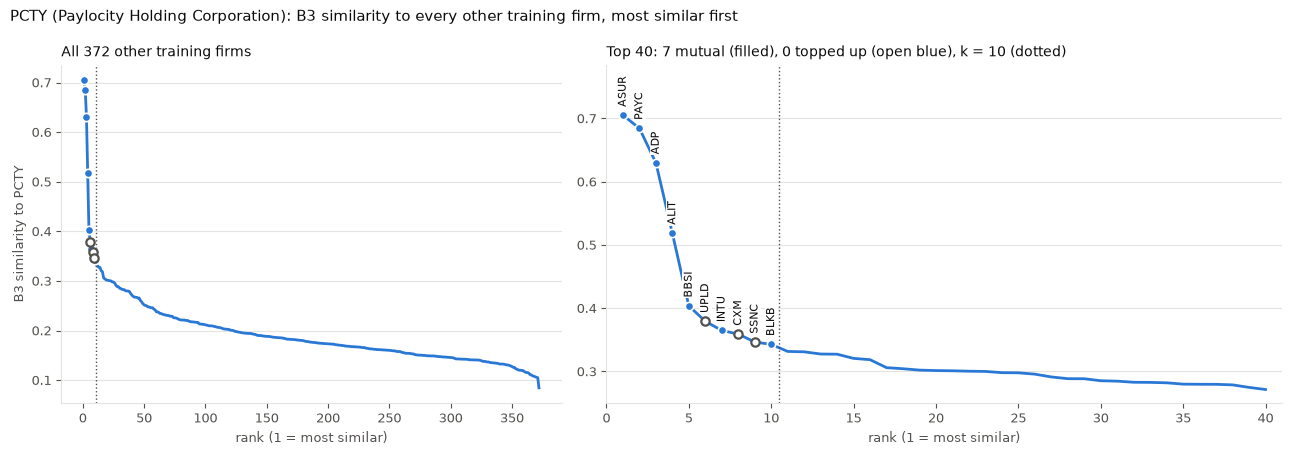

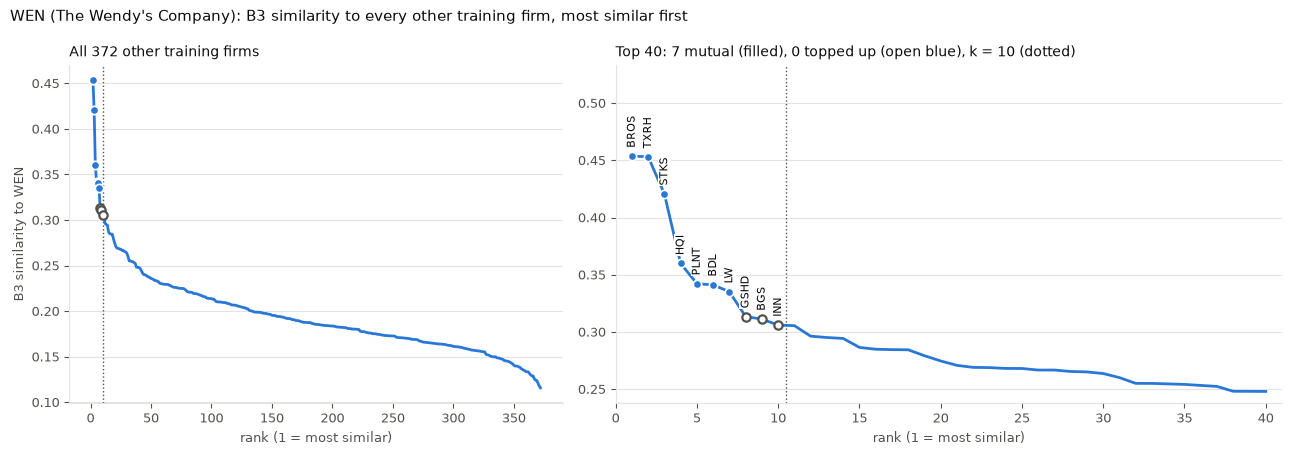

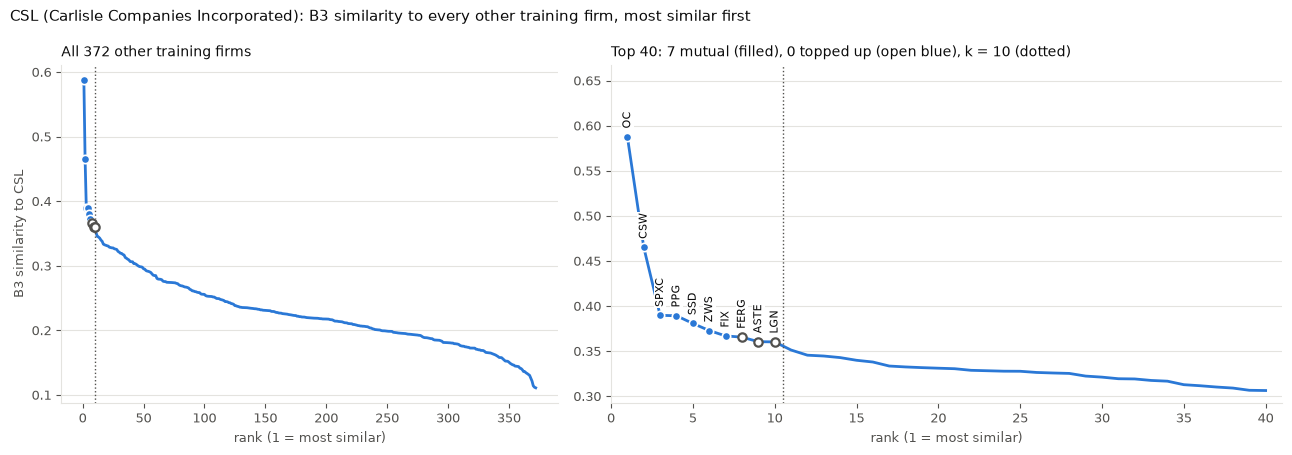

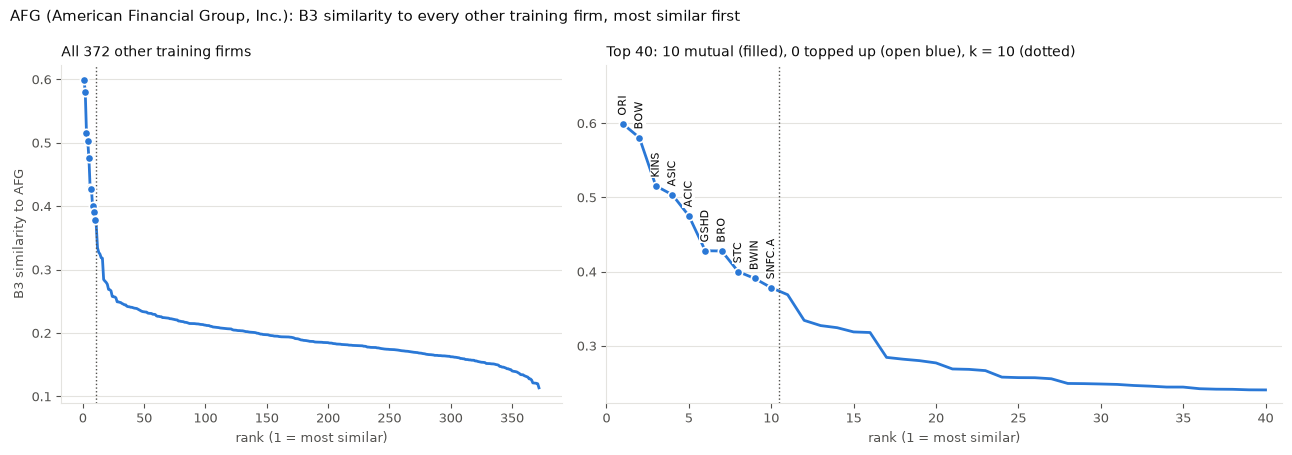

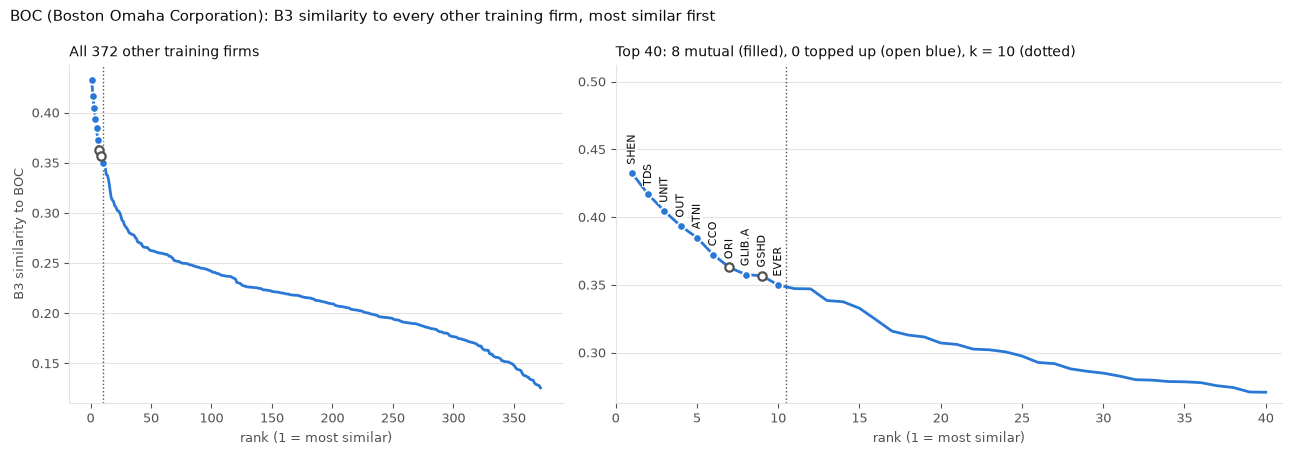

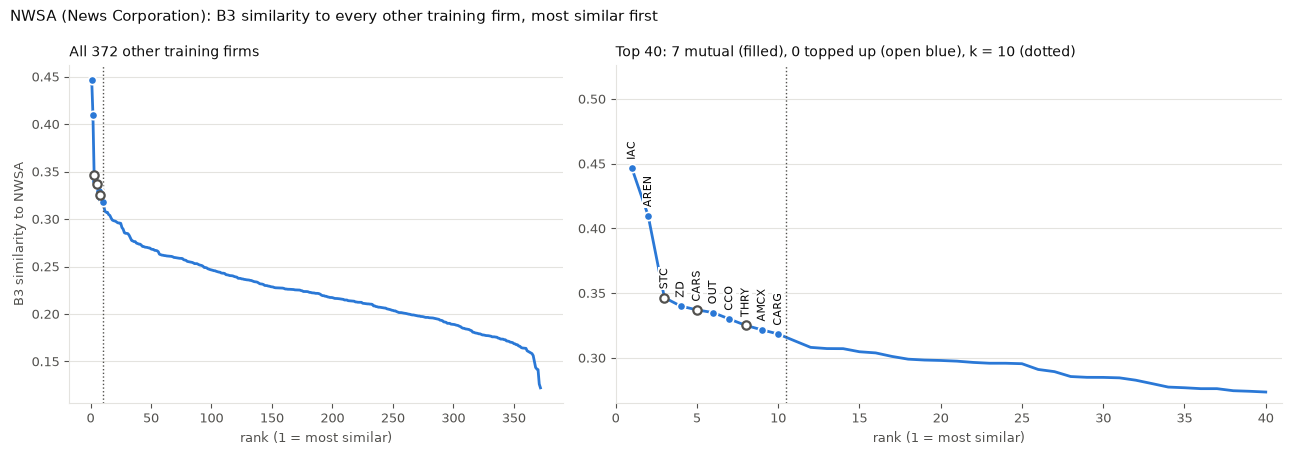

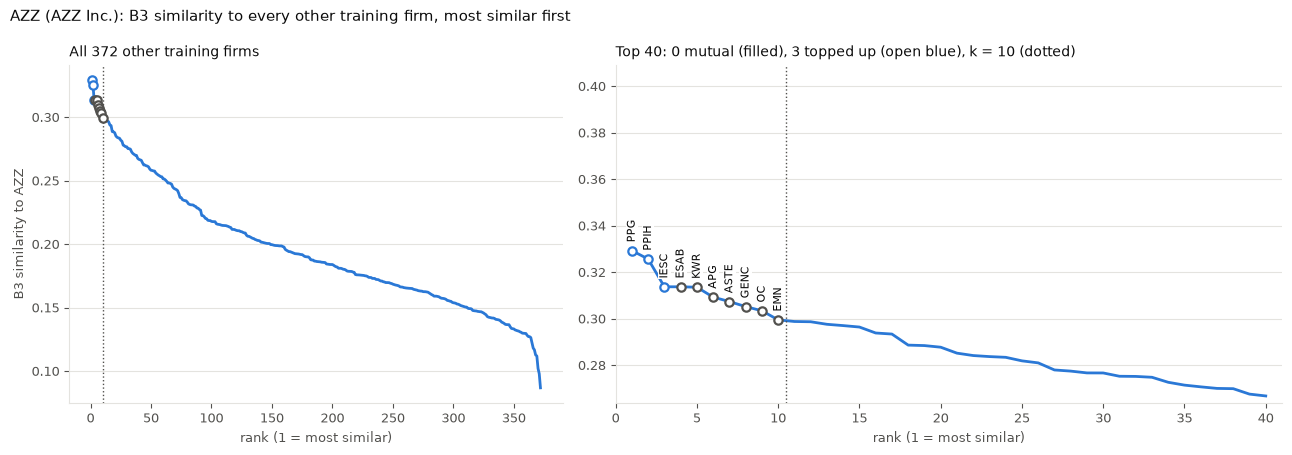

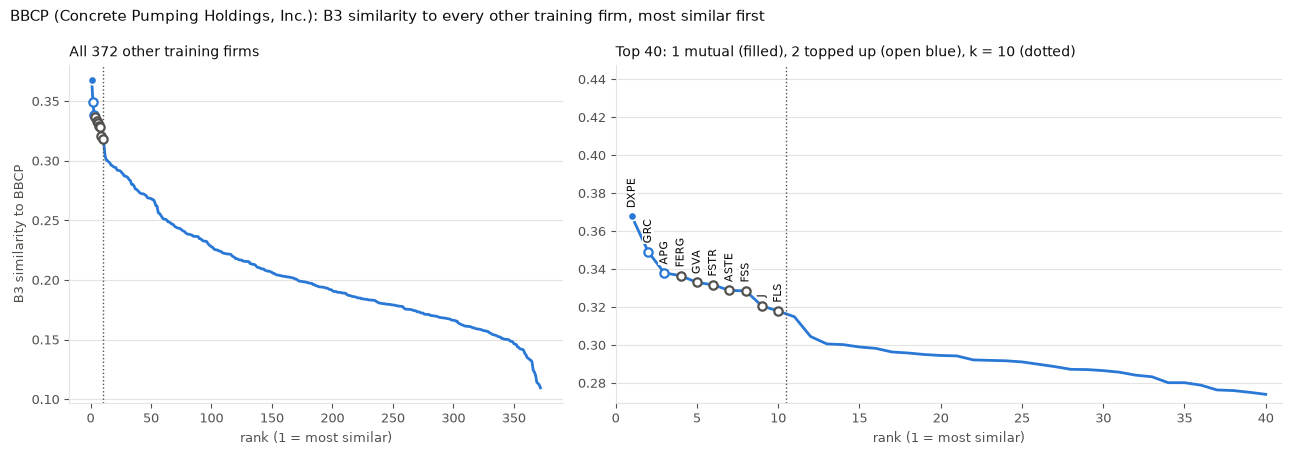

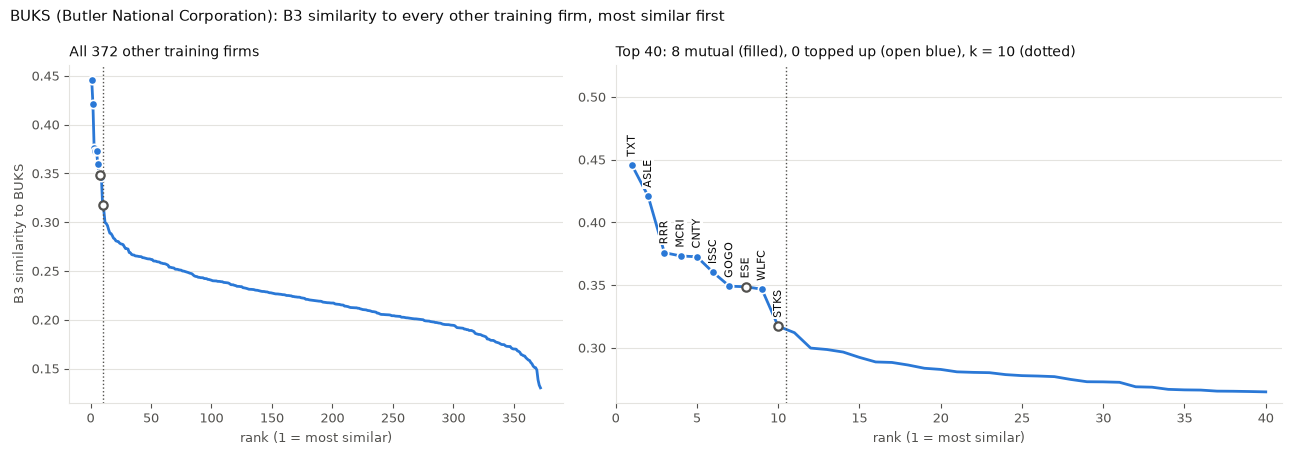

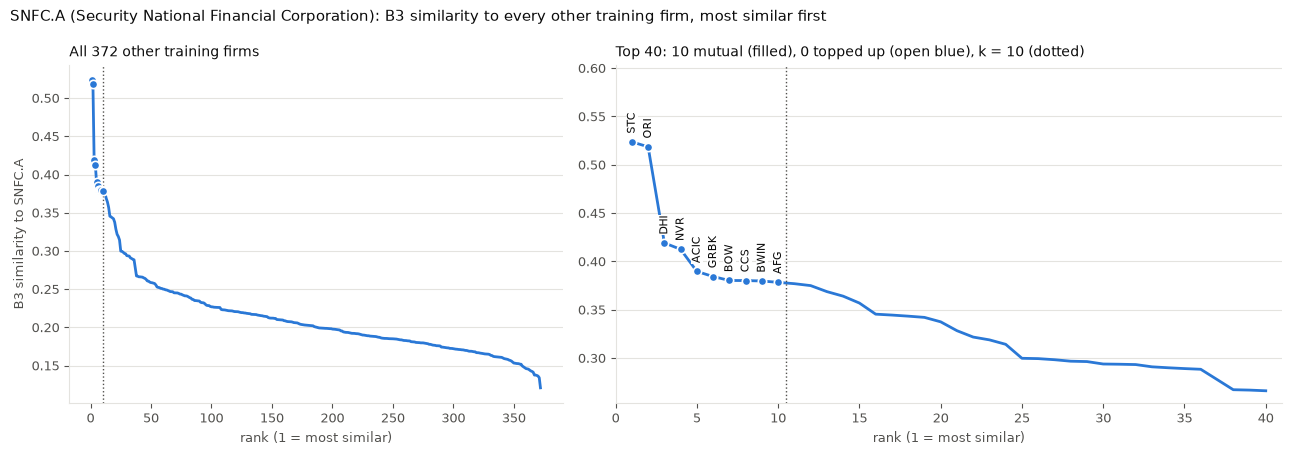

In [7]:
SHOWCASE = ["PCTY", "WEN", "CSL", "AFG", "BOC", "NWSA", "AZZ", "BBCP", "BUKS", "SNFC.A"]   # business-structure pilot targets
import matplotlib.pyplot as plt

BLUE, INK, MUTED, GRID, SURFACE = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df", "#ffffff"
ZOOM = 40
uni = pd.read_csv(paths.path(cur["universe"]["universe"]), dtype=str)
info = uni.set_index("IQ_COMPANY_ID")
id_of = dict(zip(uni["target_ciq_ticker"], uni["IQ_COMPANY_ID"]))
FALL_OUT = paths.out("03_retrieval") / "falloff" / pd.Timestamp.now("UTC").strftime("%Y%m%dT%H%M%SZ")
FALL_OUT.mkdir(parents=True, exist_ok=True)

def falloff(t):
    """Similarity of target t to every pool firm by rank (left) and the top ZOOM with the top 10 labeled (right)."""
    r = ranking[ranking["target"] == id_of[t]].assign(ticker=lambda d: d["comp"].map(info["target_ciq_ticker"]))
    r = r.merge(top[["target", "comp", "mutual", "topped_up", "selected"]], on=["target", "comp"], how="left")
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.35]})
    for ax, n in zip(axes, [len(r), ZOOM]):
        v = r.head(n)
        ax.plot(v["rank"], v["similarity"], color=BLUE, lw=2)
        marks = [(v[v["mutual"] == True], BLUE, BLUE), (v[v["topped_up"] == True], SURFACE, BLUE),   # noqa: E712
                 (v[v["in_top_k"] & (v["selected"] != True)], SURFACE, MUTED)]                     # noqa: E712
        for m, face, edge in marks:
            ax.scatter(m["rank"], m["similarity"], s=36, color=face, edgecolor=SURFACE if face == BLUE else edge,
                       linewidth=1.2 if face == BLUE else 1.6, zorder=3)
        ax.axvline(fw.TOP_K + 0.5, color=MUTED, lw=1, ls=":")
        ax.grid(axis="y", color=GRID, lw=0.8)
        ax.set_axisbelow(True)
        for side in ["top", "right"]:
            ax.spines[side].set_visible(False)
        for side in ["left", "bottom"]:
            ax.spines[side].set_color(GRID)
        ax.tick_params(colors=MUTED, labelsize=9)
        ax.set_xlabel("rank (1 = most similar)", color=MUTED, fontsize=9)
    axes[0].set_ylabel(f"B3 similarity to {t}", color=MUTED, fontsize=9)
    axes[0].set_title(f"All {len(r)} other training firms", loc="left", color=INK, fontsize=10)
    axes[1].set_title(f"Top {ZOOM}: {int((r['mutual'] == True).sum())} mutual (filled), "        # noqa: E712
                      f"{int((r['topped_up'] == True).sum())} topped up (open blue), k = {fw.TOP_K} (dotted)",  # noqa: E712
                      loc="left", color=INK, fontsize=10)
    axes[1].set_xlim(0, ZOOM + 1)
    axes[1].set_ylim(top=r["similarity"].max() + 0.08)
    for _, c in r[r["in_top_k"] & (r["rank"] <= ZOOM)].iterrows():
        axes[1].annotate(c["ticker"], (c["rank"], c["similarity"]), xytext=(0, 6), textcoords="offset points",
                         rotation=90, ha="center", va="bottom", fontsize=8, color=INK,
                         bbox=dict(fc=SURFACE, ec="none", pad=0.6))
    fig.suptitle(f"{t} ({info.loc[id_of[t], 'target_company_name']}): B3 similarity to every other training firm, "
                 "most similar first", x=0.01, ha="left", color=INK, fontsize=11)
    fig.tight_layout()
    return fig

for t in SHOWCASE:
    fig = falloff(t)
    fig.savefig(FALL_OUT / f"similarity_falloff_{t}.png", dpi=150)
    plt.show()


**Reading.** Eight of the ten showcase targets have 7-10 mutual comps on a curve that drops after the first few firms.
AZZ has no mutual comp (its three comps are all topped up) and BBCP one (DXPE, plus GRC and APG topped up). Their
curves are flat across the top 10 (BBCP: 0.37 to 0.32), the "no clear peer group" shape; both also had no
same-business comp in v1's LLM routes.


### 3.3 Similarity methods (Michael, v1 `similarity_methods.ipynb`, ported)

**What this section asks.** How B3 combines the facets into one similarity, built up one change at a time from v0's
equal-weight cosine (B0 -> B1 -> B2 -> B3), and what each change does to the comp lists and the reviewed comps.

- **B3 (method 1).** Each facet's score blends the embedding cosine with a TF-IDF word-overlap score, so boilerplate
  shared by most firms ("B2B:", "direct sales:") counts for little. Each facet is weighted by how much information
  both companies' texts carry on it, with a BM25-style saturation curve so a long facet can't dominate.
- **Current variant.** Fiona's sub-sector is a 12th facet. It has no information weight: it counts with weight 1 in
  every pair where both companies have one (as in `method1_candidates.py`), against a typical facet's ~0.5.

**Decisions applied (team, 2026-11-03).** Company size (F9) is out. "Not applicable" ("none") counts as missing.
Comps are the mutual top 10, topped up to 3 from the target's own top 10. The reviewers' scores are used under the
fixed rule in 3.7.

**What it does not do.** No API calls, nothing fitted, no EV/EBITDA (valuation of these lists is in 08).

#### Inputs

In [8]:
# v1 similarity_methods.ipynb section 0, on the current inputs (current.toml) instead of v1's Haiku fills
import json
from datetime import datetime, timezone

import numpy as np

import facets as fc
import candidates as cd
import facet_weighting as fw
import similarity_eval as se
import golden_set as gs

RUN = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
OUT = paths.out("03_retrieval") / "similarity_methods" / RUN
OUT.mkdir(parents=True, exist_ok=True)

universe = pd.read_csv(paths.path(cur["universe"]["universe"]), dtype=str)
facets = pd.read_csv(paths.path(cur["profiles"]["general"]), dtype=str).fillna("")
facets = facets[(facets["prompt_version"] == cur["profiles"]["general_prompt_version"]) & (facets["llm_status"] == "ok")]
split = pd.read_csv(paths.path(cur["universe"]["split"]), dtype=str)
training = split.loc[split["sample"] == "training", "IQ_COMPANY_ID"].tolist()
holdout = split.loc[split["sample"] == "holdout", "IQ_COMPANY_ID"].tolist()

info = universe.set_index("IQ_COMPANY_ID")
ticker = info["target_ciq_ticker"]
id_of = dict(zip(universe["target_ciq_ticker"], universe["IQ_COMPANY_ID"]))
FACETS = fw.similarity_facets()
assert FACETS == cd.SIMILARITY_FACETS, "candidates.py and facet_weighting.py disagree on the facet list"
SUB = "sub_sector"                       # v1a: Fiona's sub-sector, the 12th facet of the current variant
ALL = [*FACETS, SUB]
label = {n: f"{fc.FACET_ID[n]} {n.replace('_', ' ')}" for n in FACETS} | {SUB: "sub-sector (Fiona)"}
print(f"universe {cur['universe']['universe_run']}: {len(universe)} companies; facets {cur['profiles']['general_prompt_version']} "
      f"(Sonnet); split {cur['universe']['split_run']}: {len(training)} training, {len(holdout)} holdout")
print(f"{len(ALL)} facets in the similarity (left out: {', '.join(fw.EXCLUDED_FACETS)}):")
print(", ".join(label[n] for n in ALL))


universe 20261025T060358Z: 533 companies; facets 2026-10-25k (Sonnet); split 20261027T204930Z: 373 training, 160 holdout
12 facets in the similarity (left out: company_size):
F1 offering description, F2 primary products, F3 primary services, F4 customer segment, F5 end markets, F6 revenue model, F7 value chain position, F8 geography served, F10 specialization, F11 distribution channels, F12 regulatory exposure, sub-sector (Fiona)


In [9]:
# B0 is v0's step 4 exactly: "none" embedded as text, equal weights. v1a: on the Sonnet fills, plus the sub-sector
# (stated values only; it has no "none" text).
sector = pd.read_csv(paths.path(cur["profiles"]["sector"]), dtype=str).fillna("").set_index("IQ_COMPANY_ID")
sub_text = sector["sub_sector"].where(sector["sub_sector_status"] == "stated").replace("", np.nan)
texts_v0 = cd.facet_texts(facets).reindex(universe["IQ_COMPANY_ID"])
texts_v0[SUB] = sub_text.reindex(texts_v0.index)
ids = list(texts_v0.index)
pos = {x: i for i, x in enumerate(ids)}
emb_v0, cache_v0 = cd.embed_facets(texts_v0, paths.out("03_retrieval") / "cache")
S_B0, per_facet_v0 = cd.similarity(emb_v0)

# B1-B3: "none" as missing. Vectors come from the text-keyed caches (method1_candidates.vectors), so only texts never
# embedded before go through the local model.
texts = fw.facet_texts(facets, FACETS).reindex(ids)
texts[SUB] = sub_text.reindex(ids)
whole = {t for n in ALL for t in texts[n].dropna()}
vectors = mc.vectors(whole)
emb_cos = fw.embedding_cosines(texts, vectors)
print(f"B0 cache {cache_v0.name}; text vectors for {len(whole)} facet texts")


B0 cache facets_all-mpnet-base-v2_3d20f10c482ca6aa.npz; text vectors for 6122 facet texts


### 3.4 Diagnostics: where equal weights go wrong

Per facet, over the training firms:
- How long the texts are.
- How often the facet is "none" or unknown.
- The most common opening label: category facets start with one, such as "B2B:".
- The embedding cosine of a random pair ("none" left out), its mean and SD.
- Under v0's B0, the share of top-10 pairs that match only because both firms are "none" on the facet.

In [10]:
tr = np.array([pos[x] for x in training])
off = ~np.eye(len(tr), dtype=bool)
b0_rank = cd.rank_candidates(S_B0, ids, targets=training, pool=training)
b0_top = b0_rank[b0_rank["in_top_k"]]
rows = []
for n in ALL:
    t = texts[n].reindex(training)
    # v1a: share of all firms with a text on the facet (v1 divided by prefixed texts only, which on Sonnet texts
    # made a rare "Operates three segments:" opening look universal)
    prefix = t.dropna().str.extract(r"^([^:;]{1,30}):")[0].str.strip().value_counts() / t.notna().sum()
    C = emb_cos[n][np.ix_(tr, tr)][off]
    C = C[~np.isnan(C)]
    none = texts_v0[n].eq(cd.NOT_APPLICABLE_TEXT)
    both_none = (b0_top["target"].map(none) & b0_top["comp"].map(none)).mean()
    rows.append({"facet": label[n], "median words": t.dropna().str.split().str.len().median(),
                 "% none": 100 * texts_v0[n].reindex(training).eq(cd.NOT_APPLICABLE_TEXT).mean(),
                 "% unknown": 100 * texts_v0[n].reindex(training).isna().mean(),
                 "top label": f"{prefix.index[0]} ({prefix.iloc[0]:.0%})" if len(prefix) and prefix.iloc[0] > 0.1 else "",
                 "random-pair cosine": C.mean(), "cosine SD": C.std(),
                 "% B0 top-10 pairs both none": 100 * both_none})
diagnostics = pd.DataFrame(rows).set_index("facet")
diagnostics.round(2)

,median words,% none,% unknown,top label,random-pair cosine,cosine SD,% B0 top-10 pairs both none
facet,,,,,,,
F1 offering description,38.0,0.00,0.0,,0.38,0.12,0.00
F2 primary products,14.0,20.38,0.0,,0.23,0.14,15.98
F3 primary services,12.5,21.72,0.0,,0.30,0.14,18.15
F4 customer segment,17.0,0.00,0.0,B2B (69%),0.62,0.13,0.00
F5 end markets,9.0,0.00,0.0,,0.40,0.17,0.00
F6 revenue model,23.0,0.00,0.0,product sales (42%),0.46,0.15,0.00
F7 value chain position,25.0,0.00,0.0,OEM / manufacturer (29%),0.46,0.14,0.00
F8 geography served,12.0,0.00,0.0,global (61%),0.53,0.18,0.00
F10 specialization,13.0,0.00,0.0,related lines (89%),0.28,0.15,0.00


**Reading** (current Sonnet facets; v1's Haiku numbers are in the v1 notebook).
- **"None" matches.** F2 and F3 are "none" for 20% and 22% of training firms. Under B0, 16% and 18% of the top-10 pairs score their 1.00 on these facets only because both firms are "none".
- **Boilerplate.** Category facets open with a shared label: 69% of customer-segment texts start "B2B", 60% of distribution texts "direct sales", 61% of geography texts "global", 89% of specialization texts "related lines". A random pair already scores 0.62, 0.55 and 0.53 on the first three, against 0.23 on primary products.
- **Spread.** The cosine SDs are close, 0.12-0.18, which is why standardizing each facet's spread was dropped from the plan.
- **Sub-sector (v1a).** Fiona's sub-sector is short (median 9 words) and specific: a random pair scores 0.16, the lowest of all facets.


### 3.5 B3, built up from v0 (B0 -> B3)

##### What B0, B1, B2 and B3 mean

Method 1 is built in four steps, B0 → B1 → B2 → B3, and **each step changes exactly one thing** from the step before, so its effect can be seen on its own. B3 is method 1.

Every step computes the similarity of a target *t* and a comp *c* the same way: a weighted mean, over the facets both companies have, of their score on each facet *f*:

> **S(t, c) = Σ_f w_f(t, c) × s_f(t, c) ÷ Σ_f w_f(t, c)**

The steps differ only in the facet score *s_f* and the facet weight *w_f*:

| step | facet score s_f(t, c) | facet weight w_f(t, c) | the one change from the step before |
|---|---|---|---|
| **B0**: v0's step 4, unchanged | embedding cosine of the two facet texts; a "none" facet is embedded as the word "none" | 1 for every facet (equal weights) | (the starting point) |
| **B1**: "none" as missing | embedding cosine; a facet that is "none" for either company is skipped for that pair | 1 | two "none"s no longer match at 1.00 |
| **B2**: + information weights | as B1 | √(information(t, f) × information(c, f)) | a facet counts more when both texts say something specific on it |
| **B3**: + TF-IDF blend = **method 1** | 0.5 × embedding cosine + 0.5 × TF-IDF cosine | as B2 | the score itself discounts boilerplate words |

**The list rule is separate from the similarity.**
- **B0 one-way (v0)** takes each target's 10 most similar firms: v0's "cosine top 10" rule, the reference.
- **B0 mutual** and every later step take the **mutual top 10**, topped up to 3.

So B0 one-way vs B0 mutual isolates the list rule, and B0 mutual → B1 → B2 → B3 changes only the similarity. The tables label each step with what it adds, e.g. "B1: none as missing".

**The terms in the table:**
- **TF-IDF cosine.** Each facet text becomes a vector of word counts × IDF, and two texts are compared by cosine. IDF is BM25's, ln(1 + (N − df + 0.5) / (df + 0.5)), computed separately in each facet over the companies that have it. A word most firms use ("B2B") gets an IDF near 0; a rare word gets a high one.
- **information(t, f)** = raw ÷ (raw + K). Here raw is the summed IDF of the distinct words in *t*'s text on facet *f*, and K is the median raw over all companies and facets, so a typical facet text scores 0.5. The curve saturates: a long text gains less and less.
- **No length discount.** BM25's length discount isn't used: the cosine doesn't grow with length, and padding with common words earns almost no IDF.
- **Fixed settings.** The blend (0.5) and K are fixed in advance, not tuned on any result.

In [11]:
lex, raw_all, idfs = fw.lexical(texts)
raw_info = raw_all[FACETS]        # v1a: as in the current B3, the sub-sector gets no information weight (weighs 1)
info_score, K_SAT = fw.information(raw_info)
blended = fw.blend(emb_cos, lex)
B0_RULE = "B0 one-way (v0)"
M1 = "B3: + TF-IDF blend = method 1"
S = {B0_RULE: S_B0,                                              # equal weights, "none" as text, one-way top 10
     "B0 mutual": S_B0,                                          # same similarity, mutual top 10
     "B1: none as missing": fw.combine(emb_cos),                 # w = 1
     "B2: + information weights": fw.combine(emb_cos, info_score),   # w = sqrt(info_t x info_c)
     M1: fw.combine(blended, info_score)}                        # s = 0.5 emb + 0.5 TF-IDF, w as B2
print(f"saturation K = {K_SAT:.2f} (median summed IDF)")

# what the information weights do: each facet's share of a company's weight, against equal weights
share = info_score.div(info_score.sum(axis=1), axis=0).reindex(training)
boiler = {n: ", ".join(f"{w} {v:.1f}" for w, v in idfs[n].sort_values().head(3).items()) for n in FACETS}
weights_view = pd.DataFrame({
    "median information": info_score.reindex(training).median(),
    "mean weight share %": 100 * share.mean(),
    "equal share %": 100 / len(FACETS),
    "3 lowest-IDF words (IDF)": pd.Series(boiler)}).rename(index=label)
weights_view.round(2)

saturation K = 44.90 (median summed IDF)


,median information,mean weight share %,equal share %,3 lowest-IDF words (IDF)
F1 offering description,0.70,13.35,9.09,"and 0.0, to 0.3, sells 0.6"
F2 primary products,0.53,9.79,9.09,"and 0.3, software 1.6, products 1.9"
F3 primary services,0.46,8.57,9.09,"and 0.2, services 0.9, management 1.4"
F4 customer segment,0.52,9.89,9.09,"and 0.1, b2b 0.1, b2c 0.8"
F5 end markets,0.39,7.42,9.09,"and 0.5, healthcare 1.5, industrial 1.8"
F6 revenue model,0.56,10.48,9.09,"and 0.0, fees 0.3, service 0.5"
F7 value chain position,0.57,10.61,9.09,"and 0.0, to 0.2, sold 0.6"
F8 geography served,0.34,6.59,9.09,"and 0.1, global 0.5, states 0.6"
F10 specialization,0.47,8.93,9.09,"and 0.0, related 0.1, lines 0.1"
F11 distribution channels,0.50,9.39,9.09,"and 0.1, direct 0.2, sales 0.2"


In [12]:
# two golden-set targets: information per facet (0-1), and what that does to their weight shares
EXAMPLES = ["PCTY", "WEN"]
ex = pd.concat({t: pd.DataFrame({"text": texts.loc[id_of[t]].str.slice(0, 70),
                                 "information": info_score.loc[id_of[t]].round(2)})
                for t in EXAMPLES}, axis=1).rename(index=label)
ex

PCTY              \
                                                                                             text information   
F4 customer segment        B2B: mid-sized and small employers across industries needing payroll a        0.46   
F11 distribution channels  direct sales: in-house sales force selling to employers; partners / re        0.48   
F5 end markets             human resources and payroll across industries; healthcare; professiona        0.46   
F8 geography served        US national: Clients across the United States, with a small presence i        0.37   
F1 offering description    Provides cloud-based human capital management and payroll software to         0.69   
F2 primary products        payroll software; human resources management software; time and labor         0.55   
F3 primary services        payroll tax filing; implementation and customer support; benefits admi        0.40   
F12 regulatory exposure    medium: payroll tax filing and money movement under IRS and state tax         0.50   
F6 revenue model           subscription: recurring per-employee fees for cloud payroll and HR mod        0.63   
F10 specialization         related lines: payroll, HR, talent, time, benefits and employee engage        0.51   
sub-sector (Fiona)                           HCM, payroll and HR software for mid-sized employers         NaN   
F7 value chain position    software / platform: develops and hosts cloud HCM and payroll platform        0.55   

                                                                                              WEN              
                                                                                             text information  
F4 customer segment        B2C: individual consumers dining in, drive-thru, takeout and delivery;        0.58  
F11 distribution channels  own locations: franchised and company-operated restaurants with dine-i        0.57  
F5 end markets                                               quick-service restaurants; fast food        0.31  
F8 geography served        global: United States, Canada and international markets across Europe,        0.27  
F1 offering description    Franchises and operates Wendy's quick-service restaurants selling hamb        0.76  
F2 primary products        hamburgers; chicken sandwiches; french fries; frozen desserts; breakfa        0.51  
F3 primary services        restaurant franchising; quick-service food preparation and drive-thru         0.44  
F12 regulatory exposure    medium: food safety, labor and wage rules, franchise disclosure rules         0.42  
F6 revenue model           commissions or management fees: franchise royalties, advertising fund         0.60  
F10 specialization              niche specialist: single quick-service hamburger restaurant brand        0.43  
sub-sector (Fiona)                                  quick-service hamburger restaurant franchisor         NaN  
F7 value chain position    brand owner: franchisor licensing brand and system to independent fran        0.51

**Reading.**
- **Boilerplate is discounted.** IDF is near zero for "and", "b2b" (0.1), "direct" and "sales" (0.2), "related" and "lines" (0.1), and low for "medium" and "global" (0.5). A word used by a single firm scores about 5.9.
- **Shares move modestly.** Weight shares range from 6.6% to 13.4%, against 9.1% each for equal weights:
  - offering description gets the most (13.4%), as the longest and most specific text;
  - geography (6.6%) and end markets (7.4%) get the least, as short or generic texts.
- **Sub-sector is outside this table.** It has no information weight and counts with weight 1 wherever both firms have one, so in a pair it weighs about twice a typical facet (median information about 0.5).
- **Examples.** PCTY's geography ("US national: Clients across the United States, ...") has information 0.37. WEN's primary services now has a text in the Sonnet fills ("restaurant franchising; quick-service food preparation and drive-thru service", information 0.44); in v1's Haiku fills it was "none".


In [13]:
# Chart style (light surface). Colors were checked with the dataviz validator:
# - grades use a diverging scale: blue arm for direct/adjacent (ordinal check passed), gray midpoint, red for non-comps;
# - targets use categorical slots 1-2 (all checks passed).
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch, Patch, Rectangle

SURFACE, INK, INK2, MUTED, GRID, BASE, BAND = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#f0efec"
DIRECT, ADJACENT, NEUTRAL, NONCOMP = "#1c5cab", "#6da7ec", "#898781", "#e34948"
TARGET_COLOR = {"PCTY": "#2a78d6", "WEN": "#eb6834"}
plt.rcParams.update({"font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 9, "figure.facecolor": SURFACE,
                     "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "axes.edgecolor": BASE,
                     "axes.labelcolor": INK2, "text.color": INK, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 10, "axes.titleweight": "bold"})
FIG_OUT = OUT / "figures"   # v1a: copies; the figures live in this notebook
FIG_OUT.mkdir(exist_ok=True)
SHORT = {B0_RULE: "v0\n(one-way top 10)", "B0 mutual": "B0\nmutual", "B1: none as missing": "B1\nnone missing",
         "B2: + information weights": "B2\n+ info weights", M1: "B3\n(current)"}


def px_scale(ax):
    # data units per pixel along x and y (the layout must be final)
    ax.figure.canvas.draw()
    bb = ax.get_window_extent()
    (x0, x1), (y0, y1) = ax.get_xlim(), ax.get_ylim()
    return abs(x1 - x0) / bb.width, abs(y1 - y0) / bb.height


def hbar(ax, y, start, width, color, height_px=18, round_end=True, xpp=None, ypp=None):
    # a horizontal bar from `start` (square end) to start + width (4px rounded data end); width may be negative
    if xpp is None:
        xpp, ypp = px_scale(ax)
    h, r = height_px * ypp, 4 * xpp
    left, w = (start, width) if width >= 0 else (start + width, -width)
    if w <= 0:
        return
    if round_end and w > 2 * r:
        ax.add_patch(FancyBboxPatch((left, y - h / 2), w, h, boxstyle=f"round,pad=0,rounding_size={r}",
                                    mutation_aspect=ypp / xpp, fc=color, ec="none"))
        sq = (left + r, w - r) if width < 0 else (left, w - r)          # square the baseline end
        ax.add_patch(Rectangle((sq[0], y - h / 2), sq[1], h, fc=color, ec="none"))
    else:
        ax.add_patch(Rectangle((left, y - h / 2), w, h, fc=color, ec="none"))


def stacked_hbar(ax, y, parts, height_px=18):
    # segments left to right with a 2px surface gap between them; only the last segment gets the rounded end
    xpp, ypp = px_scale(ax)
    parts = [(w, c) for w, c in parts if w > 0]
    left = 0.0
    for k, (w, color) in enumerate(parts):
        last = k == len(parts) - 1
        hbar(ax, y, left, w - (0 if last else 2 * xpp), color, height_px, round_end=last, xpp=xpp, ypp=ypp)
        left += w

### 3.6 How the BM25 pieces curb boilerplate in B3

Method 1 borrows exactly two pieces from BM25, and this subsection shows each at work:
1. **IDF (inverse document frequency).** A word's weight is ln(1 + (N − df + 0.5) / (df + 0.5)), where df is how many firms use it in that facet. A word most firms share ("B2B", "direct sales", "medium") gets an IDF near 0. In the TF-IDF score, sharing it adds almost nothing, and it adds almost nothing to a text's information score.
2. **Saturation.** Information = raw ÷ (raw + K), where raw is the summed IDF of the text's distinct words. More specific words raise it, with diminishing returns, so a long facet can't take over.

BM25's third piece, its length discount, is not used. The embedding cosine doesn't grow with text length, and padding with common words earns almost no IDF anyway.

The four views below:
- what a common label is worth against a typical word;
- how much sharing the label raises a facet's score, before and after the TF-IDF blend;
- the saturation curve;
- one worked pair.

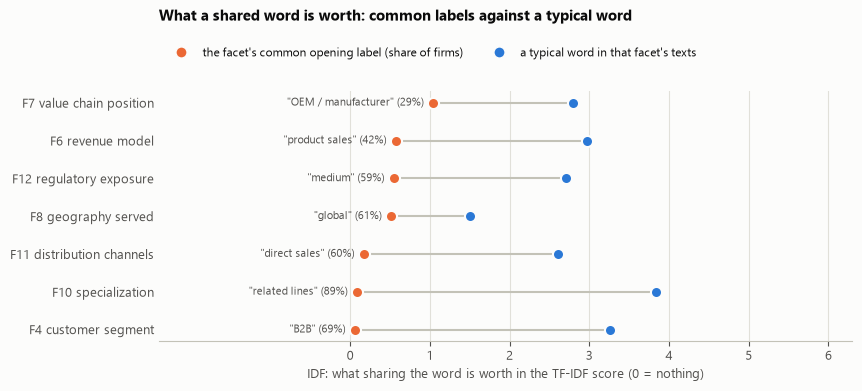

,label,share of firms,label IDF,typical word IDF (median as used),a one-firm word's IDF
facet,,,,,
F4 customer segment,B2B,0.69,0.06,3.26,5.87
F10 specialization,related lines,0.89,0.09,3.84,5.87
F11 distribution channels,direct sales,0.60,0.17,2.60,5.87
F8 geography served,global,0.61,0.52,1.51,5.87
F12 regulatory exposure,medium,0.59,0.55,2.71,5.87
F6 revenue model,product sales,0.42,0.58,2.97,5.87
F7 value chain position,OEM / manufacturer,0.29,1.04,2.80,5.87


In [14]:
import re

# each facet whose texts mostly open with the same category label (over 10% of training firms)
label_words = {}
for n in FACETS:
    pre = texts[n].reindex(training).dropna().str.extract(r"^([^:;]{1,30}):")[0].str.strip().value_counts()
    pre = pre / texts[n].reindex(training).notna().sum()   # v1a: share of all firms, as in the diagnostics table
    if len(pre) and pre.iloc[0] > 0.1:
        label_words[n] = (pre.index[0], pre.iloc[0])

rows = []
for n, (lab, share_) in label_words.items():
    idf = idfs[n]
    in_texts = [idf[w] for t in texts[n].reindex(training).dropna() for w in set(fw.tokens(t))]   # a typical word as used
    rows.append({"facet": label[n], "label": lab, "share of firms": share_,
                 "label IDF": float(np.mean([idf[w] for w in fw.tokens(lab) if w in idf])),
                 "typical word IDF (median as used)": float(np.median(in_texts)),
                 "a one-firm word's IDF": float(idf.max())})
boilerplate = pd.DataFrame(rows).set_index("facet").sort_values("label IDF")

fig, ax = plt.subplots(figsize=(9.5, 3.9))
fig.subplots_adjust(left=0.24, right=0.97, top=0.78, bottom=0.14)
y = np.arange(len(boilerplate))
ax.hlines(y, boilerplate["label IDF"], boilerplate["typical word IDF (median as used)"], color=BASE, lw=1.5, zorder=1)
ax.plot(boilerplate["label IDF"], y, "o", ms=8, mfc=TARGET_COLOR["WEN"], mec=SURFACE, mew=1.5, zorder=3)
ax.plot(boilerplate["typical word IDF (median as used)"], y, "o", ms=8, mfc=TARGET_COLOR["PCTY"], mec=SURFACE, mew=1.5, zorder=3)
for k, (lab, v, sh) in enumerate(zip(boilerplate["label"], boilerplate["label IDF"], boilerplate["share of firms"])):
    ax.text(v - 0.12, k, f"\"{lab}\" ({sh:.0%})", ha="right", va="center", fontsize=8, color=INK2)
ax.set_yticks(y, boilerplate.index)
ax.set_xlim(-2.4, 6.3)
ax.set_xticks(range(0, 7))
ax.set_xlabel("IDF: what sharing the word is worth in the TF-IDF score (0 = nothing)")
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
fig.legend(handles=[Line2D([], [], ls="", marker="o", ms=8, mfc=TARGET_COLOR["WEN"], mec=SURFACE, label="the facet's common opening label (share of firms)"),
                    Line2D([], [], ls="", marker="o", ms=8, mfc=TARGET_COLOR["PCTY"], mec=SURFACE, label="a typical word in that facet's texts")],
           loc="upper left", bbox_to_anchor=(0.24, 0.92), ncol=2, frameon=False, fontsize=8.5)
fig.suptitle("What a shared word is worth: common labels against a typical word", x=0.24, ha="left", y=0.99,
             fontsize=11, fontweight="bold")
fig.savefig(FIG_OUT / "bm25_label_idf.png", dpi=150)
plt.show()
boilerplate.round(2)

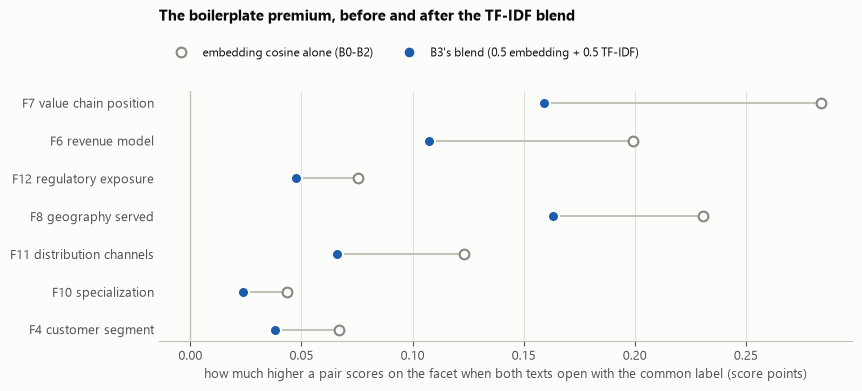

score,B3 blend,TF-IDF alone,embedding alone,B3 blend ÷ embedding
facet,,,,
F4 customer segment,0.038,0.009,0.067,0.566
F10 specialization,0.024,0.004,0.043,0.550
F11 distribution channels,0.066,0.009,0.123,0.536
F8 geography served,0.163,0.096,0.231,0.708
F12 regulatory exposure,0.048,0.020,0.075,0.630
F6 revenue model,0.107,0.016,0.199,0.540
F7 value chain position,0.159,0.035,0.284,0.562


In [15]:
# How much sharing the label raises a facet's score: mean score of training pairs that both open with the label,
# minus pairs where only one does. Embedding alone (B1/B2's score) against B3's blend (0.5 embedding + 0.5 TF-IDF).
tr_idx = np.array([pos[x] for x in training])
off_diag = ~np.eye(len(tr_idx), dtype=bool)
rows = []
for n, (lab, _) in label_words.items():
    has = texts[n].reindex(training).fillna("").str.match(rf"\s*{re.escape(lab)}\s*:").to_numpy()
    both, one = has[:, None] & has[None, :] & off_diag, (has[:, None] ^ has[None, :])
    for name, M in [("embedding alone", emb_cos[n]), ("TF-IDF alone", lex[n]), ("B3 blend", blended[n])]:
        X = M[np.ix_(tr_idx, tr_idx)]
        rows.append({"facet": label[n], "score": name, "premium": np.nanmean(X[both]) - np.nanmean(X[one])})
premium = pd.DataFrame(rows).pivot(index="facet", columns="score", values="premium").reindex(boilerplate.index)
premium["B3 blend ÷ embedding"] = premium["B3 blend"] / premium["embedding alone"]

fig, ax = plt.subplots(figsize=(9.5, 3.9))
fig.subplots_adjust(left=0.24, right=0.97, top=0.78, bottom=0.14)
y = np.arange(len(premium))
ax.hlines(y, premium["B3 blend"], premium["embedding alone"], color=BASE, lw=1.5, zorder=1)
ax.plot(premium["embedding alone"], y, "o", ms=7, mfc=SURFACE, mec=MUTED, mew=1.5, zorder=2)
ax.plot(premium["B3 blend"], y, "o", ms=8, mfc=DIRECT, mec=SURFACE, mew=1.5, zorder=3)
ax.axvline(0, color=BASE, lw=1)
ax.set_yticks(y, premium.index)
ax.set_xlabel("how much higher a pair scores on the facet when both texts open with the common label (score points)")
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
fig.legend(handles=[Line2D([], [], ls="", marker="o", ms=7, mfc=SURFACE, mec=MUTED, mew=1.5, label="embedding cosine alone (B0-B2)"),
                    Line2D([], [], ls="", marker="o", ms=8, mfc=DIRECT, mec=SURFACE, label="B3's blend (0.5 embedding + 0.5 TF-IDF)")],
           loc="upper left", bbox_to_anchor=(0.24, 0.92), ncol=2, frameon=False, fontsize=8.5)
fig.suptitle("The boilerplate premium, before and after the TF-IDF blend", x=0.24, ha="left", y=0.99,
             fontsize=11, fontweight="bold")
fig.savefig(FIG_OUT / "bm25_label_premium.png", dpi=150)
plt.show()
premium.round(3)

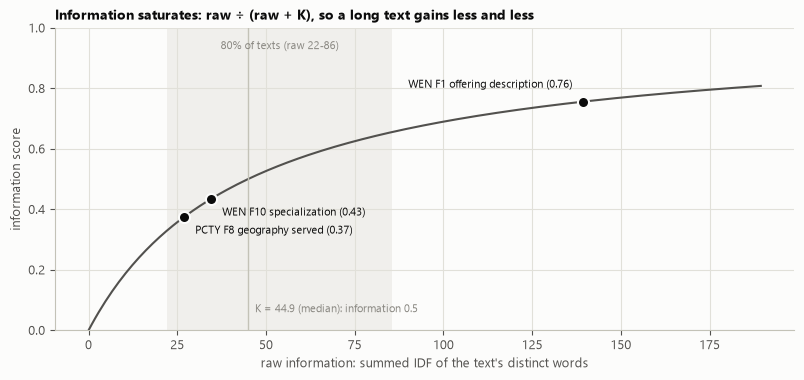

In [16]:
# Saturation: every training company-facet text, its summed IDF against its information score
raw_tr, info_tr = raw_info.reindex(training), info_score.reindex(training)
xs, ys = raw_tr.to_numpy().ravel(), info_tr.to_numpy().ravel()
keep = ~np.isnan(xs)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
fig.subplots_adjust(left=0.1, right=0.97, top=0.86, bottom=0.14)
p10, p90 = np.percentile(xs[keep], [10, 90])                  # every text lies on the curve; show where most fall
ax.axvspan(p10, p90, color=BAND, lw=0, zorder=0)
ax.text((p10 + p90) / 2, 0.93, f"80% of texts (raw {p10:.0f}-{p90:.0f})", ha="center", fontsize=8, color=MUTED)
grid_x = np.linspace(0, np.nanmax(xs) * 1.02, 200)
ax.plot(grid_x, grid_x / (grid_x + K_SAT), color=INK2, lw=1.5)
ax.axvline(K_SAT, color=BASE, lw=1)
ax.text(K_SAT + 2, 0.06, f"K = {K_SAT:.1f} (median): information 0.5", fontsize=8, color=MUTED)
for t, n in [("PCTY", "geography_served"), ("WEN", "offering_description"), ("WEN", "specialization")]:
    i = id_of[t]
    ax.plot(raw_info.at[i, n], info_score.at[i, n], "o", ms=8, mfc=INK, mec=SURFACE, mew=1.5)
    right = raw_info.at[i, n] > K_SAT * 2
    ax.annotate(f"{t} {label[n]} ({info_score.at[i, n]:.2f})", (raw_info.at[i, n], info_score.at[i, n]),
                xytext=(-8, 10) if right else (8, -12), textcoords="offset points", fontsize=8, color=INK,
                ha="right" if right else "left")
ax.set_xlabel("raw information: summed IDF of the text's distinct words")
ax.set_ylabel("information score")
ax.set_ylim(0, 1)
ax.grid(color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.set_title("Information saturates: raw ÷ (raw + K), so a long text gains less and less", loc="left")
fig.savefig(FIG_OUT / "bm25_saturation.png", dpi=150)
plt.show()

In [17]:
# One worked pair from customer segment: two firms that share only the "B2B" label, against two that share specific words
n = "customer_segment"
i_tr = [pos[x] for x in training]
has = texts[n].reindex(training).fillna("").str.match(r"\s*B2B\s*:").to_numpy()
E, L, B = (M[np.ix_(i_tr, i_tr)] for M in (emb_cos[n], lex[n], blended[n]))
pair_mask = has[:, None] & has[None, :] & off_diag
only_label = np.where(pair_mask & (L < 0.05), E - L, -np.inf)                 # high embedding, near-zero word overlap
a, b = np.unravel_index(np.argmax(only_label), only_label.shape)
specific = np.where(pair_mask, L, -np.inf)                                     # the strongest word overlap
c, d = np.unravel_index(np.argmax(specific), specific.shape)
worked = pd.DataFrame([{"pair": f"{ticker[training[x]]} – {ticker[training[y]]}", "what they share": what,
                        "text 1": texts.at[training[x], n], "text 2": texts.at[training[y], n],
                        "embedding cosine": E[x, y], "TF-IDF cosine": L[x, y], "B3 facet score": B[x, y]}
                       for x, y, what in [(a, b, "the \"B2B\" label, almost no specific words"), (c, d, "specific words")]])
with pd.option_context("display.max_colwidth", 90):
    display(worked.round(2))

,pair,what they share,text 1,text 2,embedding cosine,TF-IDF cosine,B3 facet score
0,ASH – ECVT,"the ""B2B"" label, almost no specific words","B2B: pharmaceutical, personal care, food, coatings, construction and energy product ma...","B2B: refineries, chemical and plastics producers, water treatment, mining, and semicon...",0.94,0.04,0.49
1,CCO – OUT,specific words,"B2B: advertisers, brands and advertising agencies","B2B: advertisers, brands and advertising agencies",1.00,1.00,1.00


**Reading.**
- **Labels are worth almost nothing.** The seven common opening labels have IDFs of 0.06-1.04. A typical word in the same facets is worth 1.5-3.8, and a word only one firm uses 5.9.
  - "B2B" (69% of firms) is worth 0.06, "related lines" (89%) 0.09, "direct sales" (60%) 0.17, "medium" regulatory exposure (59%) 0.55.
  - "OEM / manufacturer" (29%) keeps more weight, 1.04, because fewer firms use it. That is the intended behaviour: a rarer label says more.
- **B3 roughly halves the boilerplate premium.** Under the embedding alone, a pair whose texts open with the same common label scores 0.04-0.28 higher on that facet than a pair where only one does. B3's blend keeps 54-71% of that premium.
  - **Why about half:** half of B3's score is the TF-IDF cosine, where the label adds only 0.004-0.035 (geography 0.10).
  - **Geography keeps the most (71%),** because the rest of its text is generic too: its typical word is worth only 1.5.
- **Saturation.** A text at K (raw 44.9, the median) scores 0.5. Generic texts sit low, such as PCTY's geography at 0.37 and WEN's specialization at 0.43. A long, specific text sits high, such as WEN's offering description at 0.76. Doubling a text's raw information from K raises its score only from 0.5 to 0.67.
- **The worked pair** (customer segment):
  - **ASH and ECVT** share the "B2B" label and little that is specific: embedding cosine 0.94, TF-IDF 0.04, B3 facet score 0.49.
  - **CCO and OUT** have the same specific text ("B2B: advertisers, brands and advertising agencies"): 1.00 on all three.
- **A side effect.** The TF-IDF half also rewards shared rare words regardless of a firm's role. That is how Lamb Weston (a fries supplier) rises for WEN in 3.7.


##### Comp lists and their sizes

In [18]:
def select(Smat, targets, mutual=True):
    if not mutual:
        r = cd.rank_candidates(Smat, ids, targets=targets, pool=training)
        return r[r["in_top_k"]].assign(mutual=np.nan, topped_up=False)[["target", "comp", "rank", "similarity", "mutual", "topped_up"]]
    return fw.mutual_top_k(Smat, ids, targets, training, k=fw.TOP_K, min_comps=fw.MIN_COMPS)

sel_train = {name: select(Sm, training, mutual=name != B0_RULE) for name, Sm in S.items()}


def sizes(sel_by_method, targets):
    rows = []
    for name, sel in sel_by_method.items():
        n = sel.groupby("target").size().reindex(targets, fill_value=0)
        mutual_n = sel.groupby("target")["mutual"].sum().reindex(targets, fill_value=0)
        rows.append({"method": name, "targets": len(targets), "comps (median)": n.median(), "comps (mean)": n.mean(),
                     "% targets topped up": np.nan if sel["mutual"].isna().all() else 100 * sel.groupby("target")["topped_up"].any().reindex(targets, fill_value=False).mean(),
                     "% with 0 mutual": np.nan if sel["mutual"].isna().all() else 100 * (mutual_n == 0).mean(),
                     "% with 10 mutual": np.nan if sel["mutual"].isna().all() else 100 * (mutual_n == fw.TOP_K).mean()})
    return pd.DataFrame(rows).set_index("method")

sizes(sel_train, training).round(1)

,targets,comps (median),comps (mean),% targets topped up,% with 0 mutual,% with 10 mutual
method,,,,,,
B0 one-way (v0),373,10.0,10.0,NaN,NaN,NaN
B0 mutual,373,6.0,6.4,11.5,2.7,15.3
B1: none as missing,373,7.0,6.4,12.1,2.4,15.3
B2: + information weights,373,7.0,6.4,11.8,1.6,15.5
B3: + TF-IDF blend = method 1,373,7.0,6.8,7.5,1.6,16.6


**Reading.** Mutual top 10 gives a median of 6 comps (B0 mutual) or 7 (B1-B3), a mean of 6.4-6.8, and never more than 10. Between 7.5% (B3) and 12.1% (B1) of targets have fewer than 3 mutual comps and are topped up from their own top 10; 1.6-2.7% have none. 15-17% keep all 10.


### 3.7 The reviewers' golden set (round 1, PCTY and WEN)

**Rule for using the reviewers' scores (agreed 2026-11-03):**
1. **Source:** only the three reviewers' scores (Riya, Barbara, Matthew) on the 36 PCTY/WEN pairs (`reviewer_labels_20261028.json`). Grades: 2 = direct comp, 1 = adjacent, 0 = not a comp. No Sol or Haiku verdict enters this set.
2. **Main set (majority):** a pair's grade is the one at least 2 of the 3 reviewers gave. Pairs with three different grades are left out and listed as "no majority".
3. **Strict check (unanimous):** the pairs all three graded the same, reported separately.
4. **Unlabeled comps:** a comp in a method's list that no reviewer scored is *unlabeled*, never 0. Every metric comes with the share of the list that is labeled.
5. **Metrics:** precision@10 (share graded 1 or 2) and NDCG@10 (`golden_set.py`) on the labeled comps of each list. Beside them, as analysis:
   - which reviewed comps each list finds;
   - where every reviewed comp ranks;
   - a facet-by-facet view of WEN;
   - each reviewer on their own (a robustness check, not a replacement for the majority).
6. **Caveat:** the majority mostly reflects Barbara and Matthew, who agree on 30 of 36 pairs. Riya agrees with either of them on 12.

The 36 pairs were pooled from v0's four routes, so the new methods' lists contain comps nobody has scored. Section 8 writes those pairs to a sheet for the reviewers.

In [19]:
snapshot = json.loads(paths.src("06_labels", "round1", "reviewer_labels_20261028.json").read_text(encoding="utf-8"))
reviewer_labels = pd.DataFrame(snapshot["labels"])
majority, unanimous, no_majority = se.reviewer_sets(reviewer_labels)
print(f"snapshot fetched {snapshot['fetched_at_utc']}: {len(reviewer_labels)} pairs; majority set {len(majority)}, "
      f"unanimous {len(unanimous)}, no majority {len(no_majority)}")
pd.concat({"majority": majority.groupby([majority["target"].map(ticker), "grade"]).size(),
           "unanimous": unanimous.groupby([unanimous["target"].map(ticker), "grade"]).size()}, axis=1).fillna(0).astype(int)

snapshot fetched 2026-10-28T11:25:10.429Z: 36 pairs; majority set 32, unanimous 11, no majority 4


majority  unanimous
target grade                     
PCTY   0             5          0
       1             4          1
       2             3          3
WEN    0            16          7
       1             3          0
       2             1          0

##### The hits, at a glance

**What each method lists.** One bar per method, one segment per comp in its list, coloured by the reviewers' majority grade:
- **dark blue:** direct comp (2);
- **light blue:** adjacent (1);
- **gray:** no majority grade, or not yet reviewed;
- **red:** not a comp (0).

A good list is all blue. The text after each bar counts the good comps found, out of all those the reviewers graded 1 or 2, and the non-comps listed.

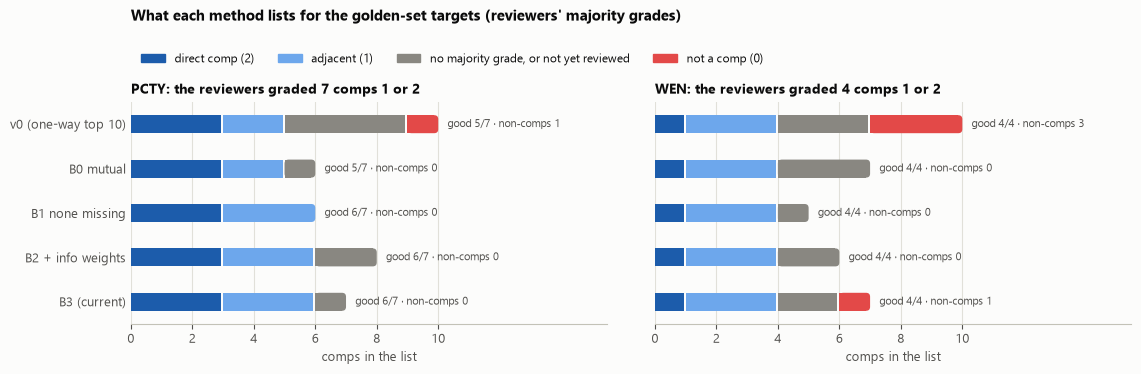

In [20]:
grade_of = {(r.target, r.comp): str(r.grade) for r in majority.itertuples()}
grade_of.update({(r.target, r.comp): "split" for r in no_majority.itertuples()})
reviewed_grades = pd.concat([majority.assign(grade=majority["grade"].astype(str)),
                             no_majority[["target", "comp"]].assign(grade="split")])
full_rank = {name: cd.rank_candidates(Sm, ids, targets=[id_of[t] for t in EXAMPLES], pool=training)
             for name, Sm in S.items()}
METHODS = list(sel_train)
KINDS = [("2", "direct comp (2)", DIRECT), ("1", "adjacent (1)", ADJACENT),
         ("?", "no majority grade, or not yet reviewed", NEUTRAL), ("0", "not a comp (0)", NONCOMP)]


def kind(t, c):
    g = grade_of.get((t, c), "?")
    return "?" if g == "split" else g


fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.7), sharey=True)
fig.subplots_adjust(left=0.12, right=0.99, top=0.74, bottom=0.14, wspace=0.1)
for ax, t in zip(axes, EXAMPLES):
    tid = id_of[t]
    ax.set_xlim(0, 15.5)
    ax.set_ylim(len(METHODS) - 0.5, -0.5)
    good_total = int((majority.loc[majority["target"] == tid, "grade"] >= 1).sum())
    for k, name in enumerate(METHODS):
        comps = sel_train[name].loc[lambda d: d["target"] == tid, "comp"]
        counts = pd.Series([kind(tid, c) for c in comps]).value_counts()
        stacked_hbar(ax, k, [(counts.get(code, 0), color) for code, _, color in KINDS])
        good = int(counts.get("2", 0) + counts.get("1", 0))
        ax.text(len(comps) + 0.3, k, f"good {good}/{good_total} · non-comps {int(counts.get('0', 0))}",
                va="center", fontsize=8, color=INK2)
    ax.set_yticks(range(len(METHODS)), [SHORT[m].replace("\n", " ") for m in METHODS])
    ax.set_xticks(range(0, 11, 2))
    ax.set_xlabel("comps in the list")
    ax.grid(axis="x", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.set_title(f"{t}: the reviewers graded {good_total} comps 1 or 2", loc="left")
fig.legend(handles=[Patch(color=c, label=l) for _, l, c in KINDS], loc="upper left", bbox_to_anchor=(0.12, 0.9),
           ncol=4, frameon=False, fontsize=8.5)
fig.suptitle("What each method lists for the golden-set targets (reviewers' majority grades)", x=0.12, ha="left",
             y=0.99, fontsize=11, fontweight="bold")
fig.savefig(FIG_OUT / "golden_hits_by_method.png", dpi=150)
plt.show()

**Where every reviewed comp ranks, step by step.** Each line is one reviewed comp, followed from v0 (left) to B3 (right). The y-axis is its rank among the 372 other training firms, best at the top, and the shaded band is the top 10.
- **Line colour:** blue for good comps (dark = direct, light = adjacent), dark gray for no majority, light gray for non-comps.
- **Filled dot:** the comp is in that step's list. A **red dot** is a non-comp that got listed.
- **Hollow blue dot:** a good comp the step missed.
- **Labels:** every comp is named on the left at its v0 rank. On the right, the good comps and any comp listed by B3 are named.


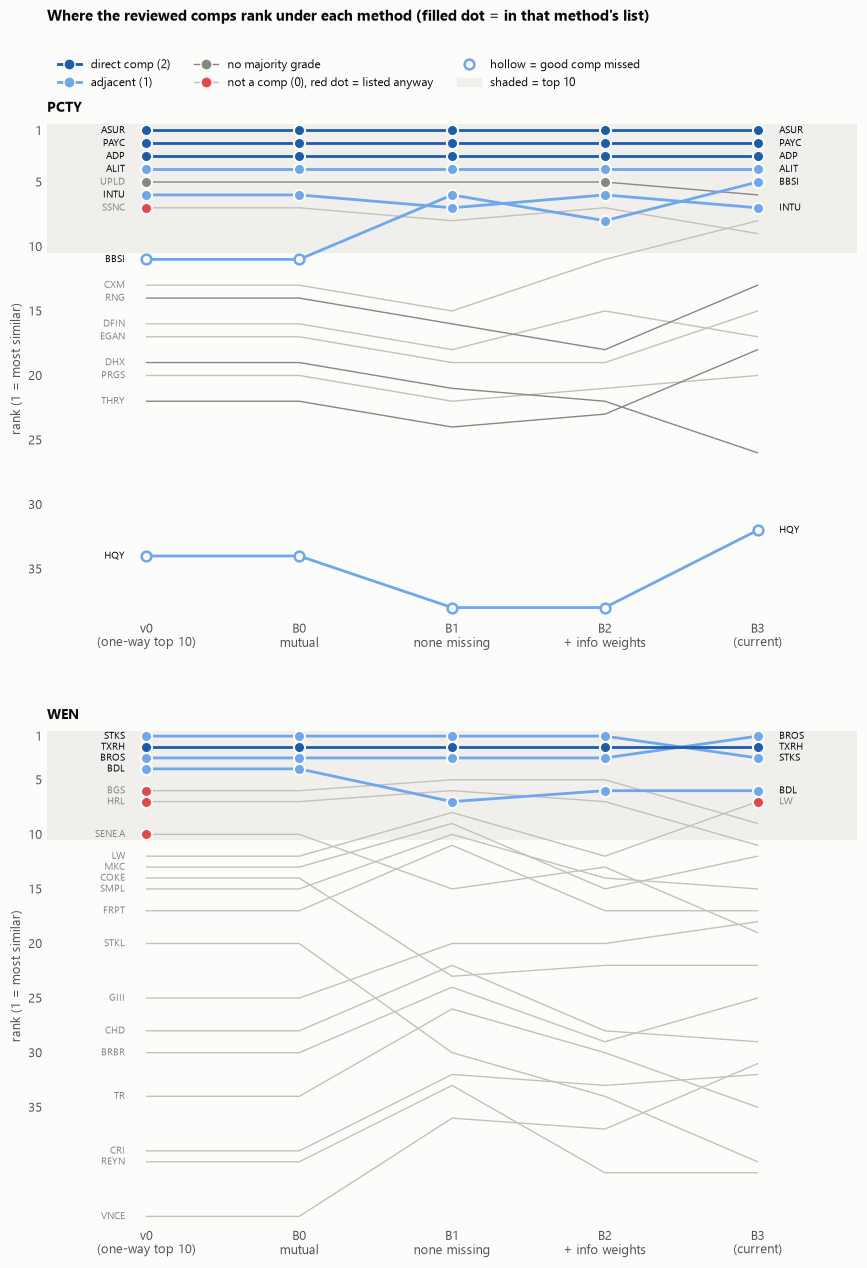

In [21]:
LINE_OF = {"2": DIRECT, "1": ADJACENT, "split": NEUTRAL, "0": BASE}
DRAW_ORDER = {"0": 0, "split": 1, "1": 2, "2": 3}
fig, axes = plt.subplots(2, 1, figsize=(10, 13))
fig.subplots_adjust(left=0.09, right=0.9, top=0.9, bottom=0.05, hspace=0.22)
x = np.arange(len(METHODS))
for ax, t in zip(axes, EXAMPLES):
    tid = id_of[t]
    rev = reviewed_grades[reviewed_grades["target"] == tid]
    ranks = pd.DataFrame({m: full_rank[m].loc[lambda d: d["target"] == tid].set_index("comp")["rank"].reindex(rev["comp"]).to_numpy()
                          for m in METHODS}, index=rev["comp"].to_numpy())
    listed = pd.DataFrame({m: rev["comp"].isin(set(sel_train[m].loc[lambda d: d["target"] == tid, "comp"])).to_numpy()
                           for m in METHODS}, index=rev["comp"].to_numpy())
    ymax = int(ranks.max().max())
    ax.axhspan(0.5, 10.5, color=BAND, lw=0, zorder=0)
    for c, g in sorted(zip(rev["comp"], rev["grade"]), key=lambda p: DRAW_ORDER[p[1]]):
        r = ranks.loc[c].to_numpy(dtype=float)
        good = g in ("1", "2")
        ax.plot(x, r, color=LINE_OF[g], lw=2 if good else 1, zorder=3 if good else 1, solid_capstyle="round")
        for xi, ri, li in zip(x, r, listed.loc[c]):
            if li:
                ax.plot(xi, ri, "o", ms=8, mfc=NONCOMP if g == "0" else LINE_OF[g], mec=SURFACE, mew=1.5, zorder=5)
            elif good:
                ax.plot(xi, ri, "o", ms=7, mfc=SURFACE, mec=LINE_OF[g], mew=1.8, zorder=4)
        ax.text(-0.14, r[0], ticker[c], ha="right", va="center", fontsize=7.5, color=INK if good else MUTED)
        if good or listed.loc[c, M1]:
            ax.text(x[-1] + 0.14, r[-1], ticker[c], ha="left", va="center", fontsize=7.5, color=INK if good else MUTED)
    ax.set_xlim(-0.65, len(METHODS) - 0.35)
    ax.set_ylim(ymax + 0.8, 0.2)
    ax.set_xticks(x, [SHORT[m] for m in METHODS])
    ax.set_yticks([1, 5, 10, 15, 20, 25, 30, 35][: 1 + ymax // 5])
    ax.set_ylabel("rank (1 = most similar)")
    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_visible(False)
    ax.tick_params(length=0)
    ax.set_title(f"{t}", loc="left")
handles = [Line2D([], [], color=DIRECT, lw=2, marker="o", ms=8, mec=SURFACE, label="direct comp (2)"),
           Line2D([], [], color=ADJACENT, lw=2, marker="o", ms=8, mec=SURFACE, label="adjacent (1)"),
           Line2D([], [], color=NEUTRAL, lw=1, marker="o", ms=8, mec=SURFACE, label="no majority grade"),
           Line2D([], [], color=BASE, lw=1, marker="o", ms=8, mfc=NONCOMP, mec=SURFACE, label="not a comp (0), red dot = listed anyway"),
           Line2D([], [], ls="", marker="o", ms=7, mfc=SURFACE, mec=ADJACENT, mew=1.8, label="hollow = good comp missed"),
           Patch(color=BAND, label="shaded = top 10")]
fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.09, 0.955), ncol=3, frameon=False, fontsize=8.5)
fig.suptitle("Where the reviewed comps rank under each method (filled dot = in that method's list)", x=0.09, ha="left",
             y=0.985, fontsize=11, fontweight="bold")
fig.savefig(FIG_OUT / "golden_ranks_by_method.png", dpi=150)
plt.show()

**Reading the two charts** (current facets).
- **PCTY.**
  - v0's list includes SSNC (red) and misses BBSI (rank 11) and HQY (rank 34).
  - From B1 on, BBSI's line climbs into the top 10 (rank 6, then 8 under B2 and 5 under B3). Treating "none" as missing removes the penalty from its "none" products.
  - B0 mutual through B3 list only blue, plus unreviewed comps (CCLD, BLKB). HQY is never found (rank 32-38 at every step).
- **WEN.**
  - v0's list has three red comps (BGS, HRL, SENE.A); the mutual filter drops them, but BGS stays inside the shaded top 10 at every step.
  - All four good comps (TXRH, STKS, BROS, BDL) are listed at every step.
  - B3 adds Lamb Weston (red): the TF-IDF blend lifts it from rank 12 (B2) to 7, and WEN is in its top 10, so it becomes a mutual comp. B3 also lists two unreviewed franchisors, HQI and PLNT.


In [22]:
rows = []
for name, sel in sel_train.items():
    m = se.list_metrics(sel, majority).assign(method=name)
    rows.append(m)
reviewer_metrics = pd.concat(rows, ignore_index=True)
reviewer_metrics["target"] = reviewer_metrics["target"].map(ticker)
reviewer_view = reviewer_metrics.pivot(index="method", columns="target",
                                       values=["listed", "labeled share", "precision@10", "NDCG@10"]).reindex(list(sel_train))
reviewer_view.round(2)

listed       labeled share       precision@10       NDCG@10     
target                          PCTY   WEN          PCTY   WEN         PCTY   WEN    PCTY  WEN
method                                                                                        
B0 one-way (v0)                 10.0  10.0          0.60  0.70         0.83  0.57    0.88  0.9
B0 mutual                        6.0   7.0          0.83  0.57         1.00  1.00    0.88  0.9
B1: none as missing              6.0   5.0          1.00  0.80         1.00  1.00    0.94  0.9
B2: + information weights        8.0   6.0          0.75  0.67         1.00  1.00    0.94  0.9
B3: + TF-IDF blend = method 1    7.0   7.0          0.86  0.71         1.00  0.80    0.94  0.9

In [23]:
strict = pd.concat([se.strict_check(sel, unanimous).assign(method=name) for name, sel in sel_train.items()])
strict["target"] = strict["target"].map(ticker)
strict.pivot(index="method", columns="target",
             values=["agreed comps listed", "agreed non-comps listed"]).reindex(list(sel_train))

agreed comps listed     agreed non-comps listed    
target                                       PCTY WEN                    PCTY WEN
method                                                                           
B0 one-way (v0)                                 3   0                       0   0
B0 mutual                                       3   0                       0   0
B1: none as missing                             3   0                       0   0
B2: + information weights                       3   0                       0   0
B3: + TF-IDF blend = method 1                   3   0                       0   0

In [24]:
# each method's list for the two targets: ticker (majority grade; "split" = no majority; "·" = unlabeled; "+" = topped up)
def lists(t):
    cols = {}
    for name, sel in sel_train.items():
        d = sel[sel["target"] == id_of[t]].sort_values("rank").head(10)
        cols[name] = pd.Series([f"{ticker[c]} ({grade_of.get((id_of[t], c), '·')}){'+' if up else ''}"
                                for c, up in zip(d["comp"], d["topped_up"])], index=range(1, len(d) + 1))
    return pd.DataFrame(cols).fillna("")

display(lists("PCTY"))
display(lists("WEN"))

,B0 one-way (v0),B0 mutual,B1: none as missing,B2: + information weights,B3: + TF-IDF blend = method 1
1,ASUR (2),ASUR (2),ASUR (2),ASUR (2),ASUR (2)
2,PAYC (2),PAYC (2),PAYC (2),PAYC (2),PAYC (2)
3,ADP (2),ADP (2),ADP (2),ADP (2),ADP (2)
4,ALIT (1),ALIT (1),ALIT (1),ALIT (1),ALIT (1)
5,UPLD (split),INTU (1),BBSI (1),UPLD (split),BBSI (1)
6,INTU (1),CCLD (·),INTU (1),INTU (1),INTU (1)
7,SSNC (0),,,BBSI (1),BLKB (·)
8,CSGS (·),,,BLKB (·),
9,BLKB (·),,,,
10,CCLD (·),,,,


,B0 one-way (v0),B0 mutual,B1: none as missing,B2: + information weights,B3: + TF-IDF blend = method 1
1,STKS (1),STKS (1),STKS (1),STKS (1),BROS (1)
2,TXRH (2),TXRH (2),TXRH (2),TXRH (2),TXRH (2)
3,BROS (1),BROS (1),BROS (1),BROS (1),STKS (1)
4,BDL (1),BDL (1),HQI (·),HQI (·),HQI (·)
5,HQI (·),HQI (·),BDL (1),BDL (1),PLNT (·)
6,BGS (0),PLNT (·),,PLNT (·),BDL (1)
7,HRL (0),IMKT.A (·),,,LW (0)
8,PLNT (·),,,,
9,IMKT.A (·),,,,
10,SENE.A (0),,,,


**Reading (2 targets, so an illustration rather than proof).**
- **WEN.** v0's list (B0 one-way) puts three majority non-comps (BGS, HRL, SENE.A) among TXRH, STKS, BROS and BDL.
  - The mutual filter alone (B0 mutual) drops them and keeps all four good comps, with precision 1.0.
  - B1 and B2 keep that; B3 lists Lamb Weston (0), so its precision is 0.80. NDCG@10 is 0.90 at every step.
- **PCTY.** v0 lists SSNC (0), giving precision 0.83. Every later step reaches 1.0, and every step keeps all 3 unanimous comps. NDCG@10 goes from 0.88 (v0) to 0.94 (B1 on).
- **Unlabeled comps.** PCTY's lists add CCLD and BLKB; WEN's add HQI (HireQuest, staffing) and PLNT (Planet Fitness). Both are franchisors, so they share WEN's franchise model but not its business. UPLD's reviewers split three ways, so it counts as unlabeled.
- **Against v1 (Haiku facets):** v1's B3 listed no non-comp for WEN. The Sonnet facets plus sub-sector bring in Lamb Weston, the same side effect v1 saw only under method 2.


##### Which reviewed comps each method finds

Counted against the majority set:
- **good:** comps graded 1 or 2;
- **direct:** comps graded 2;
- **non-comps:** comps graded 0.

The numbers read "found / reviewed". Remember the reviewed comps were pooled from v0's four routes, so "found" means found among the comps the team looked at.

In [25]:
found = reviewer_metrics.assign(
    good=reviewer_metrics["good listed"].astype(str) + " / " + reviewer_metrics["good total"].astype(str),
    direct=reviewer_metrics["direct listed"].astype(str) + " / " + reviewer_metrics["direct total"].astype(str),
    **{"non-comps listed": reviewer_metrics["non-comps listed"].astype(str) + " / "
       + reviewer_metrics["target"].map(majority.assign(t=majority["target"].map(ticker)).query("grade == 0").groupby("t").size()).astype(str)})
found.pivot(index="method", columns="target", values=["good", "direct", "non-comps listed", "listed"]).reindex(list(sel_train))

good        direct        non-comps listed         listed    
target                          PCTY    WEN   PCTY    WEN             PCTY     WEN   PCTY WEN
method                                                                                       
B0 one-way (v0)                5 / 7  4 / 4  3 / 3  1 / 1            1 / 5  3 / 16     10  10
B0 mutual                      5 / 7  4 / 4  3 / 3  1 / 1            0 / 5  0 / 16      6   7
B1: none as missing            6 / 7  4 / 4  3 / 3  1 / 1            0 / 5  0 / 16      6   5
B2: + information weights      6 / 7  4 / 4  3 / 3  1 / 1            0 / 5  0 / 16      8   6
B3: + TF-IDF blend = method 1  6 / 7  4 / 4  3 / 3  1 / 1            0 / 5  1 / 16      7   7

##### Where each reviewed comp ranks under each method

Rows are the reviewed comps, best majority grade first ("split" = no majority). Each cell is the comp's **rank among the 372 other training firms** under that method's similarity, with a mark for the list:
- **✓** in the list (mutual, or in v0's one-way top 10);
- **+** in the list by the top-up to 3;
- **×** in the top 10 but dropped because it isn't mutual;
- **no mark:** outside the top 10.

So a good comp should show a small number with ✓, and a non-comp a large number or ×.

In [26]:
rank_views = {}
for t in EXAMPLES:
    m = se.rank_matrix(full_rank, sel_train, reviewed_grades, id_of[t])
    m.index = m.index.set_levels(m.index.levels[0].map(ticker), level="comp")
    rank_views[t] = m
    print(t)
    display(m)

PCTY


,,B0 one-way (v0),B0 mutual,B1: none as missing,B2: + information weights,B3: + TF-IDF blend = method 1
comp,grade,,,,,
ASUR,2,1✓,1✓,1✓,1✓,1✓
ADP,2,3✓,3✓,3✓,3✓,3✓
PAYC,2,2✓,2✓,2✓,2✓,2✓
BBSI,1,11,11,6✓,8✓,5✓
HQY,1,34,34,38,38,32
INTU,1,6✓,6✓,7✓,6✓,7✓
ALIT,1,4✓,4✓,4✓,4✓,4✓
DHX,split,19,19,21,22,26
RNG,split,14,14,16,18,13


WEN


,,B0 one-way (v0),B0 mutual,B1: none as missing,B2: + information weights,B3: + TF-IDF blend = method 1
comp,grade,,,,,
TXRH,2,2✓,2✓,2✓,2✓,2✓
BDL,1,4✓,4✓,7✓,6✓,6✓
STKS,1,1✓,1✓,1✓,1✓,3✓
BROS,1,3✓,3✓,3✓,3✓,1✓
SENE.A,0,10✓,10×,15,13,19
VNCE,0,45,45,36,37,31
FRPT,0,17,17,11,17,17
BGS,0,6✓,6×,5×,5×,9×
STKL,0,20,20,30,34,40


##### Why WEN's list changed: its reviewed comps, facet by facet

Each reviewed WEN comp's **B0 embedding cosine on each facet**. Under B0, a "none" facet is embedded as the word "none", so two "none"s score 1.00. The last columns give the combined similarity under B0, B1 and B3.


In [27]:
wid = id_of["WEN"]
wen = reviewed_grades[reviewed_grades["target"] == wid]
wen = wen.sort_values("grade", key=lambda s: s.map({"2": 0, "1": 1, "split": 2, "0": 3}), kind="stable")
i = pos[wid]
facet_view = pd.DataFrame({label[n]: [per_facet_v0[n][i, pos[c]] for c in wen["comp"]] for n in ALL},
                          index=pd.MultiIndex.from_arrays([wen["comp"].map(ticker), wen["grade"]], names=["comp", "grade"]))
for name in [B0_RULE, "B1: none as missing", M1]:
    facet_view[f"S: {name.split(':')[0].split(' (')[0]}"] = [S[name][i, pos[c]] for c in wen["comp"]]
print(f"WEN's primary services: {texts_v0.at[wid, 'primary_services']!r} (B0) -> {texts.at[wid, 'primary_services']!r} (B1 on)")
print(f"reviewed WEN comps whose primary services is also 'none': "
      f"{', '.join(ticker[c] for c in wen['comp'] if texts_v0.at[c, 'primary_services'] == cd.NOT_APPLICABLE_TEXT)}")
facet_view.round(2)

WEN's primary services: 'restaurant franchising; quick-service food preparation and drive-thru service' (B0) -> 'restaurant franchising; quick-service food preparation and drive-thru service' (B1 on)
reviewed WEN comps whose primary services is also 'none': BROS, VNCE, FRPT, BGS, GIII, TR, REYN, BRBR, SMPL, MKC, LW, CRI, HRL, CHD


,,F1 offering description,F2 primary products,F3 primary services,F4 customer segment,F5 end markets,F6 revenue model,F7 value chain position,F8 geography served,F10 specialization,F11 distribution channels,F12 regulatory exposure,sub-sector (Fiona),S: B0 one-way,S: B1,S: B3
comp,grade,,,,,,,,,,,,,,,
TXRH,2,0.48,0.19,0.79,0.70,0.79,0.84,0.89,0.61,0.52,0.91,0.64,0.52,0.66,0.70,0.45
BDL,1,0.38,0.53,0.84,0.59,0.64,0.87,0.76,0.43,0.46,0.83,0.51,0.35,0.60,0.60,0.34
STKS,1,0.60,0.19,0.75,0.82,0.60,0.83,0.88,0.59,0.56,0.87,0.71,0.55,0.66,0.70,0.42
BROS,1,0.59,0.54,0.08,0.90,0.82,0.78,0.73,0.42,0.71,0.86,0.93,0.36,0.64,0.69,0.45
SENE.A,0,0.41,0.63,0.19,0.81,0.58,0.64,0.58,0.74,0.37,0.61,0.71,0.23,0.54,0.54,0.28
VNCE,0,0.26,0.40,0.08,0.82,0.35,0.46,0.73,0.70,0.31,0.72,0.42,0.22,0.46,0.49,0.26
FRPT,0,0.34,0.56,0.08,0.79,0.61,0.41,0.55,0.76,0.54,0.68,0.62,0.24,0.52,0.55,0.28
BGS,0,0.45,0.66,0.08,0.70,0.68,0.44,0.79,0.64,0.47,0.61,0.77,0.50,0.57,0.61,0.31
STKL,0,0.32,0.62,0.24,0.69,0.70,0.56,0.43,0.65,0.31,0.54,0.72,0.24,0.50,0.50,0.25


**Reading** (current facets).
- **F3 under B0.** In the Sonnet fills WEN's primary services has a text, so the v1 problem (every "none" comp matching WEN at 1.00) is gone. The reverse remains: 14 of its 20 reviewed comps are "none" on F3 and score 0.08 against WEN's text under B0, BROS (a good comp) included. B1 skips those pairs instead of penalizing them.
- **The facet that separates best.** Revenue model (F6) scores 0.78-0.87 for the four good comps and 0.33-0.64 for all 16 non-comps.
- **The combined score.** Under B3 the good comps score 0.34-0.45 and the best non-comp, Lamb Weston, 0.34: BDL and LW tie, which is why LW enters the list.


#### Which facets set the good comps apart under B3

v1 drew this chart for method 2. B3's similarity is also a sum of per-facet parts: for a target t and comp c,

> **part_f(t, c) = w_f(t, c) x s_f(t, c) / sum_g w_g(t, c)**, with w_f = sqrt(information(t, f) x information(c, f))
> (1 for the sub-sector) and s_f the facet's blended score; the parts add up to S(t, c).

For each target, each bar is the average part of its reviewed good comps (majority grade 1 or 2) minus that of its
reviewed non-comps (grade 0). The bars add up to how much higher the good comps score in total.

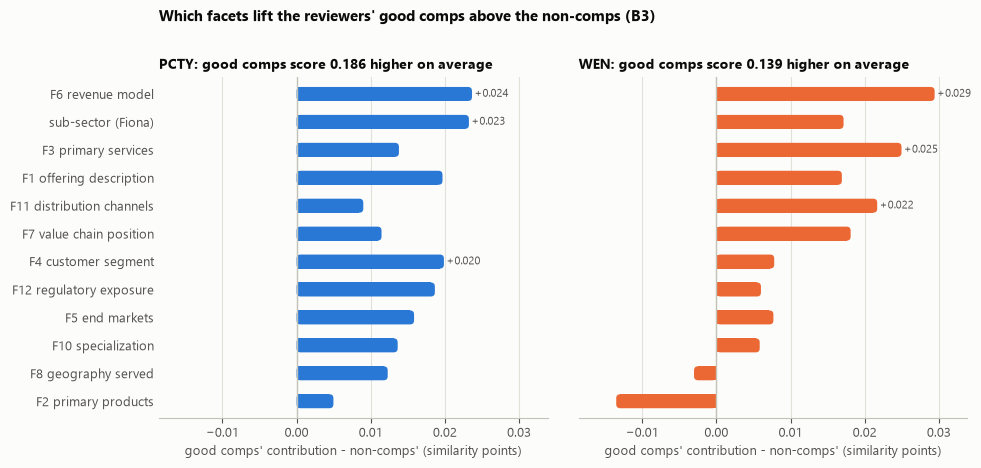

,PCTY,WEN
F1 offering description,0.020,0.017
F2 primary products,0.005,-0.013
F3 primary services,0.014,0.025
F4 customer segment,0.020,0.008
F5 end markets,0.016,0.008
F6 revenue model,0.024,0.029
F7 value chain position,0.011,0.018
F8 geography served,0.012,-0.003
F10 specialization,0.014,0.006
F11 distribution channels,0.009,0.022


In [28]:
def contributions(t):
    tid, i = id_of[t], pos[id_of[t]]
    rev = reviewed_grades[(reviewed_grades["target"] == tid) & reviewed_grades["grade"].isin(["0", "1", "2"])]
    rows = {}
    for c, g in zip(rev["comp"], rev["grade"]):
        j = pos[c]
        s = pd.Series({f: blended[f][i, j] for f in ALL})
        w = pd.Series({f: np.sqrt(np.nan_to_num(info_score.at[tid, f]) * np.nan_to_num(info_score.at[c, f]))
                       if f in info_score else 1.0 for f in ALL})
        shared = s.notna()
        part = (w[shared] * s[shared] / w[shared].sum()).reindex(ALL).fillna(0.0)
        assert np.isclose(part.sum(), S[M1][i, j])                 # the parts add up to B3's similarity
        rows[(ticker[c], g)] = part
    return pd.DataFrame(rows).T


separation = {}
for t in EXAMPLES:
    con = contributions(t)
    grades_ = con.index.get_level_values(1)
    separation[t] = con[grades_.isin(["1", "2"])].mean() - con[grades_ == "0"].mean()
separation = pd.DataFrame(separation)
order = separation.mean(axis=1).sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.8), sharey=True)
fig.subplots_adjust(left=0.2, right=0.97, top=0.84, bottom=0.13, wspace=0.08)
lim = 1.15 * separation.abs().max().max()
lo = min(0.0, separation.min().min()) * 1.3 - 0.03 * lim
for ax, t in zip(axes, EXAMPLES):
    ax.set_xlim(lo, lim)
    ax.set_ylim(-0.6, len(order) - 0.4)
    vals = separation[t].reindex(order)
    for k, v in enumerate(vals):
        hbar(ax, k, 0, v, TARGET_COLOR[t], height_px=14)
        if pd.isna(texts.at[id_of[t], order[k]]):
            ax.text(0.01 * lim, k, "missing: skipped", va="center", fontsize=8, color=MUTED)
    for f in vals.abs().sort_values().index[-3:]:                      # label the three largest only
        k, v = list(order).index(f), vals[f]
        ax.text(v + (0.01 * lim if v >= 0 else -0.01 * lim), k, f"{v:+.3f}", va="center",
                ha="left" if v >= 0 else "right", fontsize=8, color=INK2)
    ax.axvline(0, color=BASE, lw=1)
    ax.set_yticks(range(len(order)), [label[n] for n in order])
    ax.set_xlabel("good comps' contribution - non-comps' (similarity points)")
    ax.grid(axis="x", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.set_title(f"{t}: good comps score {separation[t].sum():.3f} higher on average", loc="left")
fig.suptitle("Which facets lift the reviewers' good comps above the non-comps (B3)", x=0.2, ha="left",
             y=0.98, fontsize=11, fontweight="bold")
fig.savefig(FIG_OUT / "b3_facet_separation_pcty_wen.png", dpi=150)
plt.show()
separation.rename(index=label).round(3)


##### Robustness: each reviewer on their own

The majority set mostly reflects Barbara and Matthew. Scoring each method against each reviewer's own grades shows whether the picture holds for all three. This is a check beside the rule, not a replacement for it.

In [29]:
rows = []
for r in se.REVIEWERS:
    grades_r = se.single_reviewer(reviewer_labels, r)
    for name, sel in sel_train.items():
        rows.append(se.list_metrics(sel, grades_r).assign(method=name, reviewer=r))
per_reviewer = pd.concat(rows, ignore_index=True)
per_reviewer["target"] = per_reviewer["target"].map(ticker)
per_reviewer["good found"] = per_reviewer["good listed"].astype(str) + "/" + per_reviewer["good total"].astype(str)
display(per_reviewer.pivot(index="method", columns=["target", "reviewer"], values="precision@10").reindex(list(sel_train)).round(2))
per_reviewer.pivot(index="method", columns=["target", "reviewer"], values="good found").reindex(list(sel_train))

target,WEN,PCTY,WEN,PCTY,WEN,PCTY
reviewer,riya,riya,barbara,barbara,matthew,matthew
method,,,,,,
B0 one-way (v0),1.0,1.0,0.57,0.86,0.57,0.71
B0 mutual,1.0,1.0,1.00,1.00,1.00,1.00
B1: none as missing,1.0,1.0,1.00,1.00,1.00,1.00
B2: + information weights,1.0,1.0,1.00,1.00,1.00,0.86
B3: + TF-IDF blend = method 1,1.0,1.0,0.80,1.00,0.80,1.00


target,WEN,PCTY,WEN,PCTY,WEN,PCTY
reviewer,riya,riya,barbara,barbara,matthew,matthew
method,,,,,,
B0 one-way (v0),7/13,7/16,4/4,6/11,4/4,5/7
B0 mutual,4/13,5/16,4/4,5/11,4/4,5/7
B1: none as missing,4/13,6/16,4/4,6/11,4/4,6/7
B2: + information weights,4/13,7/16,4/4,7/11,4/4,6/7
B3: + TF-IDF blend = method 1,5/13,6/16,4/4,6/11,4/4,6/7


**Reading: what the B0 -> B3 steps do to the reviewed comps** (majority set unless noted; 2 targets; current facets).

1. **Direct comps: every step finds all of them.** PCTY's ASUR, PAYC and ADP rank 1-3 at every step, and WEN's TXRH ranks 2.
2. **Adjacent comps.**
   - **PCTY:** v0 and B0 mutual find 5 of 7 good comps; B1, B2 and B3 find 6 of 7. BBSI is recovered by the "none" fix (rank 11 -> 5-8). HQY is never found.
   - **WEN:** every step finds 4 of 4.
3. **Non-comps: the mutual filter removes most of them.**
   - **v0 lists** 1 of PCTY's 5 reviewed non-comps (SSNC) and 3 of WEN's 16. B0 mutual, B1 and B2 list none; B3 lists Lamb Weston for WEN.
   - **Several are still in the top 10 by similarity:** SSNC and CXM for PCTY, BGS for WEN (the x marks). They are dropped only because the target isn't in *their* top 10.
4. **One side effect of the TF-IDF blend.** Lamb Weston (frozen potato products) shares rare words with WEN ("french fries", "quick-service restaurants") as a supplier to restaurants, not a restaurant. The word score can't tell who sells to whom. On the Sonnet facets this is enough to make it a mutual comp under B3.
5. **Robustness: two reviewers agree, one doesn't.**
   - **Barbara and Matthew,** each on their own: v0's precision@10 is 0.57 for WEN and 0.71-0.86 for PCTY; B3's is 0.80 for WEN and 1.0 for PCTY.
   - **Riya's grades don't separate the steps** (precision 1.0 everywhere): she grades most of WEN's food makers as adjacent, so v0's longer list finds more of her good comps (WEN 7 of 13, B3 5 of 13).
6. **B3's facets for the two targets** (chart above): PCTY's good comps score 0.186 higher in total, spread over many facets (revenue model 0.024, sub-sector 0.023, offering and customers 0.020 each). WEN's score 0.139 higher, led by revenue model (0.029), primary services (0.025) and distribution channels (0.022); primary products pulls the other way (-0.013), since the food makers share WEN's product words.

**In short.** On the current facets the steps keep every direct comp, recover BBSI, and drop v0's non-comps, mostly through the mutual filter. The information weights add nothing measurable here, and the TF-IDF blend costs one non-comp for WEN.


#### The build-up on Barbara's 293 pairs (v1a)

The same list metrics against `dev_293` (45 targets, one reviewer). These pairs were drawn from the current B3 list,
so B3's lists are almost fully labeled and the earlier steps' lists less so; compare precision on the labeled comps
together with the labeled share, and read it as a check, not a contest.

In [30]:
import cohorts
dev = cohorts.load("dev_293").rename(columns={"target_id": "target", "comp_id": "comp"})[["target", "comp", "grade"]]
dev["grade"] = dev["grade"].astype(int)
rows = []
for name, sel_ in sel_train.items():
    m = se.list_metrics(sel_[sel_["target"].isin(set(dev["target"]))], dev).assign(method=name)
    rows.append(m)
dev_metrics = pd.concat(rows)
num = dev_metrics.select_dtypes("number").columns
dev_metrics.groupby("method", sort=False)[num].mean().round(3)


,listed,labeled,labeled share,precision@10,direct share,NDCG@10,good total,good listed,direct total,direct listed,non-comps listed
method,,,,,,,,,,,
B0 one-way (v0),10.000,5.133,0.513,0.717,0.094,0.851,4.489,3.733,0.533,0.533,1.400
B0 mutual,6.422,4.622,0.734,0.753,0.106,0.840,4.489,3.444,0.533,0.533,1.178
B1: none as missing,6.200,5.467,0.868,0.708,0.086,0.870,4.489,3.867,0.533,0.533,1.600
B2: + information weights,6.089,5.222,0.847,0.719,0.088,0.868,4.489,3.756,0.533,0.533,1.467
B3: + TF-IDF blend = method 1,6.511,6.511,1.000,0.681,0.076,0.954,4.489,4.489,0.533,0.533,2.022


**Reading.** On Barbara's 45 targets, B3's lists are fully labeled (these pairs came from B3), with precision 0.68 and NDCG@10 0.95; it lists all 4.5 good comps per target and 2.0 non-comps. The earlier steps' precision (0.71-0.75) is on half to 87% of their lists, so it is not comparable: their unlabeled comps are never counted as non-comps. A fair comparison needs labels on the other steps' unlabeled comps.


#### Saved outputs (copies; the results above live in this notebook)

In [31]:
def ticked(d):
    return d.assign(target_ticker=d["target"].map(ticker), comp_ticker=d["comp"].map(ticker))

pd.concat([ticked(sel).assign(method=name, sample="training") for name, sel in sel_train.items()]).to_csv(OUT / "comp_lists.csv", index=False)
info_score.to_csv(OUT / "information.csv")
diagnostics.to_csv(OUT / "diagnostics.csv")
weights_view.to_csv(OUT / "information_weights.csv")
reviewer_metrics.to_csv(OUT / "reviewer_metrics.csv", index=False)
strict.to_csv(OUT / "reviewer_strict_check.csv", index=False)
per_reviewer.to_csv(OUT / "reviewer_metrics_per_reviewer.csv", index=False)
pd.concat(rank_views, names=["target"]).to_csv(OUT / "reviewed_comp_ranks.csv")
facet_view.to_csv(OUT / "wen_reviewed_comps_by_facet.csv")
separation.to_csv(OUT / "b3_facet_separation.csv")
dev_metrics.to_csv(OUT / "dev_293_metrics.csv", index=False)
SHOWCASE = ["PCTY", "WEN", "CSL", "AFG", "BOC", "NWSA", "AZZ", "BBCP", "BUKS", "SNFC.A"]
pd.concat([cd.rank_candidates(Sm, ids, targets=[id_of[t] for t in SHOWCASE], pool=training)
           [["target", "rank", "comp", "similarity"]].assign(method=name) for name, Sm in S.items()]
          ).to_csv(OUT / "rankings_showcase.csv.gz", index=False)
(OUT / "run.json").write_text(json.dumps({
    "run": RUN, "universe_run": cur["universe"]["universe_run"], "split_run": cur["universe"]["split_run"],
    "facets_version": cur["profiles"]["general_prompt_version"], "variant": cur["retrieval"]["variant"],
    "facets": ALL, "excluded_facets": list(fw.EXCLUDED_FACETS), "none_as_missing": True,
    "embedding_model": cd.EMBED_MODEL, "b0_embedding_cache": cache_v0.name,
    "alpha": fw.ALPHA, "saturation_k": K_SAT, "top_k": fw.TOP_K, "min_comps": fw.MIN_COMPS,
    "reviewer_snapshot": {k: snapshot[k] for k in ("source", "sheet", "range", "fetched_at_utc")}, "api_calls": 0,
}, indent=1), encoding="utf-8")
print("wrote", OUT.relative_to(ROOT))


wrote outputs-local\v2\03_retrieval\similarity_methods\20261124T095641Z


### 3.10 Facet add/drop (Eric, v1a run without holdout labels)

Each variant changes one facet source or bundle; the rule is fixed. `human_majority` is the 32-pair round-1 majority
set (PCTY, WEN); `haiku_screen_diagnostic` is the saved Haiku screen (a model, not people). Unlabeled pairs are never
negatives.

In [32]:
metrics = pd.read_csv(addrop / "metrics.csv")
show = ["B3 Haiku", "B3 Sonnet", "Sonnet + Fiona sub-sector", "Sonnet + Fiona categories", "Sonnet + Barbara SIC2 facets",
        "Sonnet + FF49", "Sonnet + SIC4", "Sonnet + all additions"]
cols = ["pairwise_accuracy", "good_recall", "direct_recall", "labeled_bad_selected"]
table = metrics[metrics["variant"].isin(show) & metrics["label_source"].isin(["human_majority", "haiku_screen_diagnostic"])]
table.pivot(index="variant", columns="label_source", values=cols).reindex(show).round(3)

pairwise_accuracy                            good_recall                          direct_recall                 \
label_source                 haiku_screen_diagnostic human_majority haiku_screen_diagnostic human_majority haiku_screen_diagnostic human_majority   
variant                                                                                                                                             
B3 Haiku                                       0.938          0.982                   0.961          1.000                     NaN            1.0   
B3 Sonnet                                      0.936          0.939                   0.953          0.909                     NaN            1.0   
Sonnet + Fiona sub-sector                      0.935          0.947                   0.958          0.909                     NaN            1.0   
Sonnet + Fiona categories                      0.937          0.956                   0.946          0.909                     NaN            1.0   
Sonnet + Barbara SIC2 facets                   0.931          0.939                   0.944          0.909                     NaN            1.0   
Sonnet + FF49                                  0.899          0.886                   0.878          0.818                     NaN            1.0   
Sonnet + SIC4                                  0.915          0.912                   0.902          0.727                     NaN            1.0   
Sonnet + all additions                         0.895          0.877                   0.856          0.727                     NaN            1.0   

                                labeled_bad_selected                 
label_source                 haiku_screen_diagnostic human_majority  
variant                                                              
B3 Haiku                                      1532.0            0.0  
B3 Sonnet                                     1357.0            1.0  
Sonnet + Fiona sub-sector                     1409.0            1.0  
Sonnet + Fiona categories                     1348.0            1.0  
Sonnet + Barbara SIC2 facets                  1360.0            1.0  
Sonnet + FF49                                 1184.0            0.0  
Sonnet + SIC4                                 1236.0            0.0  
Sonnet + all additions                        1179.0            0.0

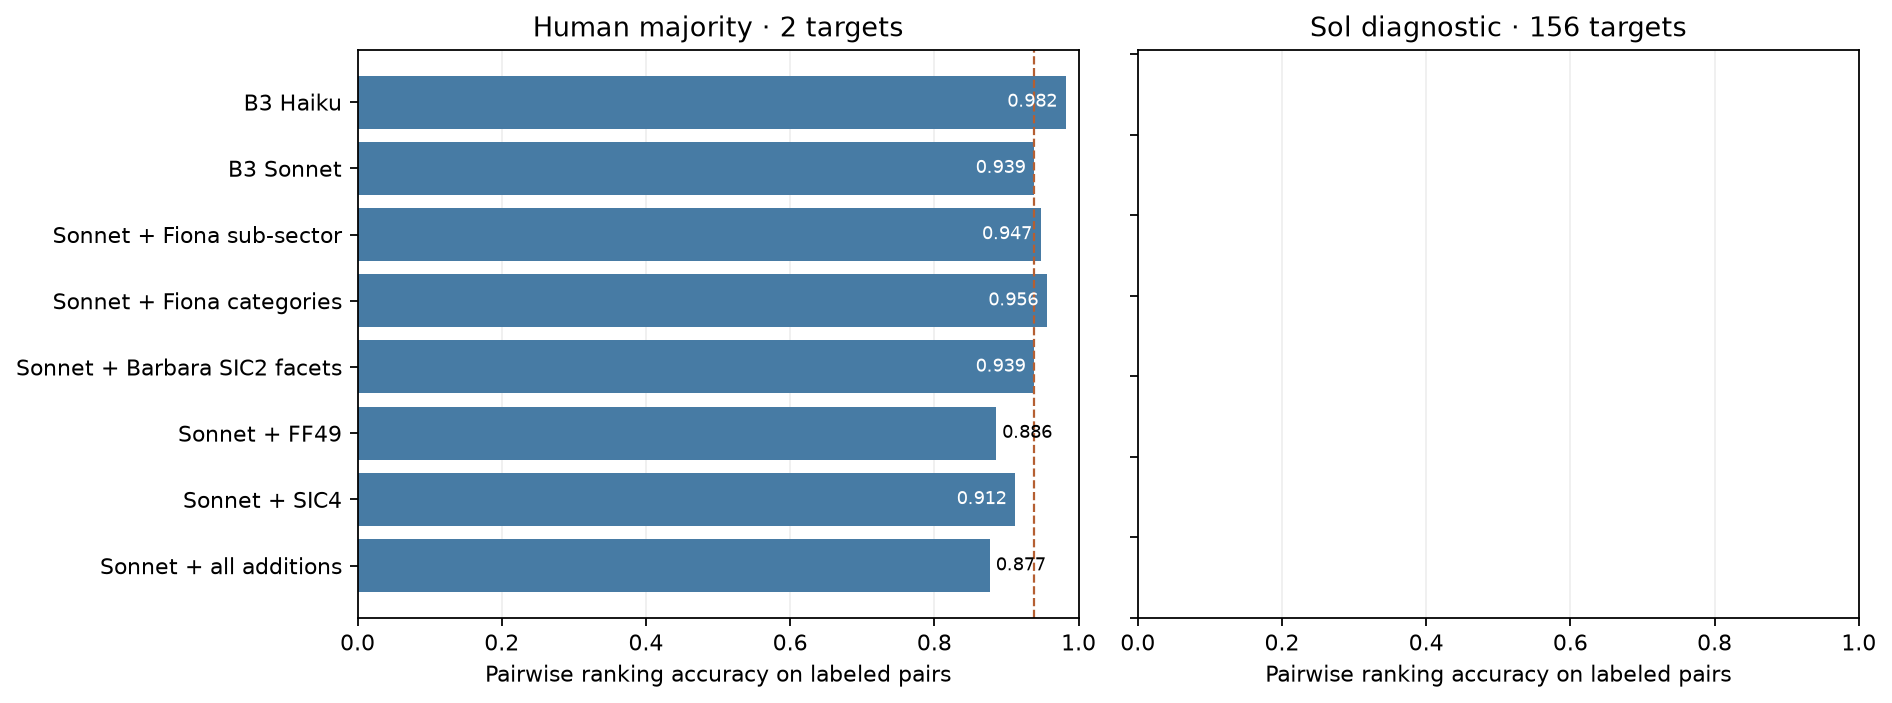

In [33]:
from IPython.display import Image
Image(filename=str(addrop / "pairwise_accuracy.png"), width=900)

## 4. Checks against the saved v1 numbers

In [34]:
saved = pd.read_csv(cand / "candidates.csv", dtype={"target": str, "comp": str})
saved_rank = pd.read_csv(cand / "ranking.csv.gz", dtype={"target": str, "comp": str})
a = set(zip(saved.loc[saved["selected"], "target"], saved.loc[saved["selected"], "comp"]))
sel_cur = top[top["selected"]]   # v1a: `sel` is reused by the ported cells
b = set(zip(sel_cur["target"], sel_cur["comp"]))
checks.add("selected comp lists identical to the saved list", a == b and len(a) == 2538, f"{len(b)} pairs")
m = ranking.merge(saved_rank, on=["target", "comp"], suffixes=("", "_saved"))
diff = float((m["similarity"] - m["similarity_saved"]).abs().max())
checks.add("similarities match (max difference < 1e-6)", len(m) == len(saved_rank) and diff < 1e-6, f"{diff:.1e} over {len(m)} pairs")
moved = m[m["rank"] != m["rank_saved"]]
ties = all(((ranking["target"] == r.target) & ((ranking["similarity"] - r.similarity).abs() < 1e-7)).sum() >= 2 for r in moved.itertuples())
checks.add("rank differences are exact ties outside the top 10", ties and (moved["rank"] > fw.TOP_K).all(), f"{len(moved)} rows")
v1_eval = pd.read_csv(paths.src("03_retrieval", "facet_add_drop_eval", "metrics.csv"))
v1_eval = v1_eval[v1_eval["label_source"] != "sol_holdout_diagnostic"].reset_index(drop=True)
num = v1_eval.select_dtypes("number").columns
same = v1_eval[["variant", "label_source"]].equals(metrics[["variant", "label_source"]]) and \
       float((v1_eval[num] - metrics[num]).abs().max().max()) == 0
checks.add("add/drop metrics equal v1's (without the holdout rows)", same, f"{len(metrics)} rows")
same_b3 = np.allclose(np.nan_to_num(S[M1], nan=-9), np.nan_to_num(S_cur, nan=-9), atol=1e-9)
checks.add("3.3's B3 step equals the current B3 similarity (method1_candidates)", same_b3)
checks.add("3.3's B3 comp lists equal the current list",
           set(zip(sel_train[M1]["target"], sel_train[M1]["comp"])) == b)
checks.show()

6/6 checks pass


,check,result,detail
0,selected comp lists identical to the saved list,pass,2538 pairs
1,similarities match (max difference < 1e-6),pass,1.1e-07 over 138756 pairs
2,rank differences are exact ties outside the top 10,pass,10 rows
3,add/drop metrics equal v1's (without the holdout rows),pass,180 rows
4,3.3's B3 step equals the current B3 similarity (method1_candidates),pass,
5,3.3's B3 comp lists equal the current list,pass,


## 5. History (v1)

- `v1/notebooks/similarity_methods.ipynb` (2026-11-03/04) compared v0's cosine with method 1 (= B3) and method 2
  (FAME-inspired gates); method 2 was about method 1. B3 became the v1 baseline on comp quality. It also replaced
  v0's z >= 2 rule with the mutual top 10, and made "none" missing.
- The add/drop experiment (2026-11-05) produced the current list: on the 32 majority pairs Haiku B3 selects 11/11
  good and 0 bad, Sonnet B3 10/11 and 1 bad; Fiona's sub-sector leaves those counts unchanged.
- The 11-10 integration study ran 20 retrieval rules on three facet sources; it stays in v1 (index in `09_analysis`).
- Valuation comparisons of these lists belong to `08_valuation`.
- What stayed in v1 from `similarity_methods.ipynb`: method 2 (sections 3 and its charts; dropped 11-03), Sol's
  holdout grades (section 5), valuation (section 6; 08 values the current lists), the facet-label check on Haiku
  texts (section 7) and the round-2 sheet (section 8). Its v1 numbers (Haiku fills) stay in the v1 notebook.
